# Notebook 7 — Whole-brain tiling of the noise mechanism

We leave the single patch behind. The release is one **global** statistic map (voxelwise group
mean / median / variance) plus a **whole-brain noise field** assembled patch by patch from the
frozen per-patch mechanism (the mode-space eigendecomposition mechanism, 6.5). Where patches overlap, a voxel's noise is
combined from every patch covering it.

**This notebook is constructive + diagnostic, not a privacy evaluation.** Per the meeting, the
per-patch membership question is set aside; the point now is how the *assembled* field behaves as we
vary patch size, shape, and overlap — the object a later privacy eval would attack.

**Substrate.** The committed outputs run on a portable synthetic phantom so they reproduce anywhere;
the real target is **OASIS gray-matter maps** (`USE_OASIS=True`). The synthetic phantom is a testing
stand-in — all interpretation below is written for the OASIS case, and the auto-generated read-offs
recompute from whichever substrate is active.

Conventions: multi-seed with 95% CIs on scalar summaries, concepts in Markdown and result-dependent
interpretation in printed read-offs, and the frozen modules verified byte-unchanged.

## 0 · Setup, configuration, frozen-module check

All sweep dimensions live here. `PROFILE='fast'` is the portable committed run; `'full'` + `USE_OASIS=True`
(with nilearn) is the heavy real-data sweep. `CUSTOM_SIZES` is the hook for the sizes your
autocorrelation notebook (6.3) settles on.

In [1]:
import os
# Pin BLAS to ONE thread per process BEFORE importing numpy. The per-patch matrices are tiny in the
# mode space (r = min(p, N-1) <= 39), so BLAS multithreading is pure overhead and oversubscribes
# cores. Real parallelism is across PATCHES via joblib n_jobs below.
for _v in ("OMP_NUM_THREADS","OPENBLAS_NUM_THREADS","MKL_NUM_THREADS","NUMEXPR_NUM_THREADS","VECLIB_MAXIMUM_THREADS"):
    os.environ[_v] = "1"
import hashlib, time, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.lines import Line2D
import tiling as T
import privacy_harness as ph
import mode_eigen_mech as ME

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 120, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False})

# the three support modules must stay byte-unchanged (mode_eigen_mech / tiling are ours and may evolve)
FROZEN = {
    "privacy_harness.py": "f03e766b265b4b0b253ce3a8eb94cb53ea76662544ea0b1b9db102f8f29015b4",
    "cov_diagnostics.py": "d91b33cf7e532ee676d16532830ea65f263a5c0277cc4bd34d768908d2601013",
    "inference_eval.py":  "0bd08830469858a9332a5cfddc6c332a894dc318b09efda42a9ba8fa6c2b2018"}
for f, h in FROZEN.items():
    assert hashlib.sha256(open(f, "rb").read()).hexdigest() == h, f"FROZEN MODULE CHANGED: {f}"
print("frozen modules verified byte-unchanged:", ", ".join(FROZEN))

frozen modules verified byte-unchanged: privacy_harness.py, cov_diagnostics.py, inference_eval.py


In [2]:
# ================= configuration =================
PROFILE   = "full"          # 'fast' = portable committed run; 'full' = heavy sweep (user env)
USE_OASIS = True            # True -> real OASIS gray-matter maps (needs nilearn); the real study

N        = 40               # cohort size (N-1 = 39 is the LOO rank ceiling)
EPSILON  = 1.0              # per-patch mechanism scale reference (factor = 2/eps); not a DP guarantee
MIN_FRAC = 0.5              # a patch is 'well-estimated' if >= this fraction is in-brain; boundary
                            # patches below it are still added as needed so every voxel gets noise
NJOBS    = 16               # cores here (near the throughput knee from §7; raise/lower to taste)

# ---- per-patch mechanism: the validated mode-space eigendecomposition mechanism (notebook 6.4) ----
# It draws correlated noise as one coefficient per covariance eigenmode and NEVER forms the p x p
# covariance, so it scales to the large (OASIS-size) patches the old voxel mechanisms OOM on.
MECH_KIND    = "mode-eigen"     # 'mode-eigen' (new) | 'supervisor' | 'l2' (legacy voxel bars)
MECH_SCALE   = 3.0              # per-mode noise scale  (the 6.4 operating point)
MECH_KCHECK  = 26              # rejection depth k_check = full min(p,N-1) (deviates from 6.4 k_check=26, by choice)
MECH_MAXDRAWS = 5000           # rejection-sampler draw budget

# ---- brain mask source ----
MASK_SOURCE  = "data"          # 'data' = union GM support (default) | 'mni152_gm' = MNI152 GM mask (OASIS only)
COVER_HOLES  = True            # boundary coverage pass: True = no privacy holes; False = threshold patches only (see §2)

SHAPES = {
    # "3x3x3": (3,3,3),
    # "4x4x4": (4,4,4),
    "8x8x8": (8,8,8),
    "12x12x12": (12,12,12),
    "16x16x16": (16,16,16),
          # larger cubic sizes the new mechanism unblocks
    # "8x8x1": (8,8,1),
    "32x16x1": (32,16,1)
}             # extreme-anisotropic shapes stress the tiling
DISP   = {
    # "3x3x3":"3³",
    # "4x4x4":"4³",
    "8x8x8":"8³",
    "12x12x12":"12³",
    "16x16x16":"16³",
    # "8x8x1":"8×8×1",
    "32x16x1":"32×16×1"
}
OVERLAPS = [0.0, 0.25, 0.5]
STATS    = ["mean", "median", "variance"]
PIPES    = {"mean": ph.pipeline_mean, "median": ph.pipeline_median, "variance": ph.pipeline_variance}

GM_THRESHOLD = "otsu"          # OASIS 'data' mask: "otsu" (auto) or a float GM-probability cutoff
# your 6.3 autocorrelation-derived sizes + a scaled-down anisotropic (43x30x31 / ANISO_DIVISOR)
ANISO_DIVISOR = 2
_aniso_small = tuple(max(1, int(round(d / ANISO_DIVISOR))) for d in (43, 30, 31))   # -> (22,15,16)
CUSTOM_SIZES   = {"custom_35x35x35": (35,35,35), "custom_43x30x31": (43,30,31),
                  f"custom_{_aniso_small[0]}x{_aniso_small[1]}x{_aniso_small[2]}": _aniso_small}
CUSTOM_OVERLAPS = [0.0, 0.25, 0.5]        # committed run keeps custom light; add 0.75 in your env

if PROFILE == "fast":
    PH_SHAPE = (24, 24, 20); SEEDS = (0, 1, 2)
else:
    PH_SHAPE = (48, 48, 40); SEEDS = (0, 1, 2)

# ---- visual system (CVD-safe Okabe-Ito; median=green, variance=orange per request) ----
C_STAT  = {"mean":"#0072B2", "median":"#009E73", "variance":"#E69F00"}
M_STAT  = {"mean":"o", "median":"s", "variance":"^"}
C_BLEND = {"sum":"#555555", "average":"#D55E00", "pou":"#CC79A7", "pou_energy":"#56B4E9"}
BL_DISP = {"sum":"sum (no averaging)", "average":"plain average",
           "pou":"partition-of-unity", "pou_energy":"energy-preserving POU"}
BLENDS_REL = ["average", "pou", "pou_energy"]            # the release blends used for utility
BLENDS_ALL = ["sum", "average", "pou", "pou_energy"]     # all four, for the §3 comparison
CMAP_MAG, CMAP_CNT, CMAP_RANK, CMAP_DIV = "magma", "viridis", "viridis", "RdBu_r"
print(f"PROFILE={PROFILE}  USE_OASIS={USE_OASIS}  mechanism={MECH_KIND} "
      f"(scale={MECH_SCALE}, k_check={MECH_KCHECK}, max_draws={MECH_MAXDRAWS})  mask={MASK_SOURCE}")
print(f"sizes: {list(SHAPES)}  custom: {list(CUSTOM_SIZES)}")

# --- scaled-down anisotropic custom patch: make the rounding explicit (item 1) ---
_ab = (43, 30, 31)
_exact = tuple(d / ANISO_DIVISOR for d in _ab)
_ratio_in  = tuple(round(d / _ab[1], 3) for d in _ab)
_ratio_out = tuple(round(d / _aniso_small[1], 3) for d in _aniso_small)
print(f"scaled-down custom: {_ab} / {ANISO_DIVISOR}  ->  exact {tuple(round(e,2) for e in _exact)}  "
      f"->  rounded {_aniso_small}")
print(f"  proportions {_ratio_in} -> {_ratio_out}  (43 and 31 are odd, so x,z round up by 0.5 voxel; "
      f"the exact 2:1 ratios the even axis allows are preserved, the odd axes drift <=3%)")

# --- matched-volume family for 5b (shape at FIXED 64-voxel volume); always available, so the
#     matched-volume comparison survives any change to SHAPES (item 1 breakage fix) ---
MATCHED_SHAPES = {"4x4x4": (4, 4, 4), "8x8x1": (8, 8, 1), "2x2x16": (2, 2, 16)}  # each = 64 voxels
MATCHED_DISP   = {"4x4x4": "4³", "8x8x1": "8×8×1", "2x2x16": "2×2×16"}

PROFILE=full  USE_OASIS=True  mechanism=mode-eigen (scale=3.0, k_check=26, max_draws=5000)  mask=data
sizes: ['8x8x8', '12x12x12', '16x16x16', '32x16x1']  custom: ['custom_35x35x35', 'custom_43x30x31', 'custom_22x15x16']
scaled-down custom: (43, 30, 31) / 2  ->  exact (21.5, 15.0, 15.5)  ->  rounded (22, 15, 16)
  proportions (1.433, 1.0, 1.033) -> (1.467, 1.0, 1.067)  (43 and 31 are odd, so x,z round up by 0.5 voxel; the exact 2:1 ratios the even axis allows are preserved, the odd axes drift <=3%)


In [3]:
# ---- build the substrate (phantom committed; OASIS behind the flag) ----
t0 = time.perf_counter()
if USE_OASIS:
    SUB = T.load_oasis_volumes(n=max(N, 100)); SUBSTRATE = "OASIS gray-matter maps"
else:
    SUB = T.make_phantom(shape=PH_SHAPE, M=2*N, N=N, corr_lens=(2.0,4.0,6.0),
                         zone_amp=(1.0,0.7,1.3), seed=0)
    SUBSTRATE = f"synthetic phantom {PH_SHAPE} (test substrate)"

# --- brain mask ---------------------------------------------------------------------------------
# OASIS ships NO brain mask (fetch_oasis_vbm returns only gray/white maps + metadata). The harness'
# default (finite AND nonzero in ANY subject) UNIONS every subject's near-zero background and ends up
# flagging ~all of the volume -- useless. So for OASIS we build a real GM mask by thresholding the
# MEAN gray-matter map (Otsu by default), then filling holes and keeping the largest connected
# component. For the phantom the harness mask is already clean, so we keep it.
from scipy import ndimage as _ndi
def _gm_threshold_mask(volumes, how="otsu"):
    gm_mean = np.asarray(volumes, float).mean(0)
    finite = np.isfinite(gm_mean) & (gm_mean > 0)
    if how == "otsu":
        try:
            from skimage.filters import threshold_otsu
            thr = float(threshold_otsu(gm_mean[finite])) if finite.any() else 0.0
        except Exception:
            thr = float(np.percentile(gm_mean[finite], 60)) if finite.any() else 0.0
    else:
        thr = float(how)
    m = _ndi.binary_fill_holes(gm_mean > thr)
    lab, n = _ndi.label(m)
    if n > 1:                                   # keep the largest connected blob (the brain)
        sizes = _ndi.sum(np.ones_like(lab), lab, range(1, n + 1))
        m = lab == (1 + int(np.argmax(sizes)))
    return m & np.isfinite(gm_mean), thr

if USE_OASIS:
    MASK_DATA, _gm_thr = _gm_threshold_mask(SUB["volumes"], GM_THRESHOLD)
    print(f"GM-threshold data mask: cutoff={_gm_thr:.3f}  ({MASK_DATA.mean()*100:.0f}% of volume)")
else:
    MASK_DATA = SUB["mask"]                     # phantom mask is already clean
MASK_MNI  = None
if MASK_SOURCE == "mni152_gm" and USE_OASIS:
    try:
        from nilearn.datasets import load_mni152_gm_mask, fetch_oasis_vbm
        from nilearn.image import resample_to_img
        import nibabel as nib
        ref = nib.load(fetch_oasis_vbm(n_subjects=1).gray_matter_maps[0])   # OASIS grid + affine
        gm_r = resample_to_img(load_mni152_gm_mask(), ref, interpolation="nearest")
        MASK_MNI = (np.asarray(gm_r.get_fdata()) > 0) & MASK_DATA           # keep only where data exists
    except Exception as e:
        print("MNI152 GM mask unavailable, falling back to the data mask:", e)
MASK = MASK_MNI if (MASK_SOURCE == "mni152_gm" and MASK_MNI is not None) else MASK_DATA
VOLSHAPE = MASK.shape
COHORT = {s: T.sample_cohort(SUB, N, seed=s) for s in SEEDS}   # one cohort per seed (CI variability)
print(f"substrate: {SUBSTRATE}  |  mask='{MASK_SOURCE}'  in-brain voxels {int(MASK.sum())}/{MASK.size} "
      f"({MASK.mean()*100:.0f}%)  |  built in {time.perf_counter()-t0:.1f}s")

[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
GM-threshold data mask: cutoff=0.002  (31% of volume)
substrate: OASIS gray-matter maps  |  mask='data'  in-brain voxels 283966/902629 (31%)  |  built in 6.1s


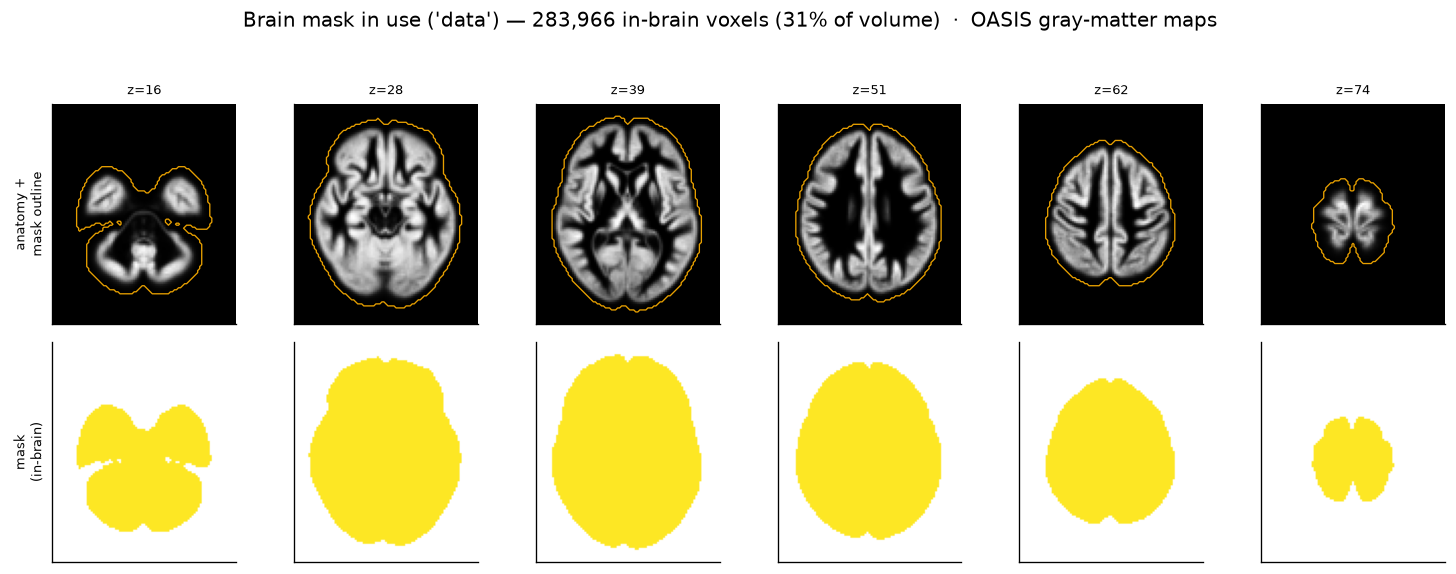

[read-off] the mask should hug gray matter with no interior holes and no off-brain inclusion; anything odd here would confound every downstream tiling/coverage/rank result.


In [4]:
# Brain-mask check — montage of axial slices (mask outline over mean anatomy, and the mask itself), so we
# can rule out a mask confound (holes, off-brain inclusion) before any tiling.
_mean_anat = COHORT[SEEDS[0]].mean(0)
_zs = np.unique(np.linspace(VOLSHAPE[2]*0.18, VOLSHAPE[2]*0.82, 6).astype(int))
fig, axes = plt.subplots(2, len(_zs), figsize=(2.1*len(_zs), 4.6), squeeze=False)
for j, zz in enumerate(_zs):
    a0 = axes[0, j]; a0.imshow(_mean_anat[:, :, zz].T, origin="lower", cmap="gray"); a0.set_xticks([]); a0.set_yticks([]); a0.grid(False)
    a0.contour(MASK[:, :, zz].T, levels=[0.5], colors="#E69F00", linewidths=0.8); a0.set_title(f"z={zz}", fontsize=8)
    a1 = axes[1, j]; a1.imshow(np.where(MASK, 1.0, np.nan)[:, :, zz].T, origin="lower", cmap="viridis", vmin=0, vmax=1)
    a1.set_xticks([]); a1.set_yticks([]); a1.grid(False)
axes[0, 0].set_ylabel("anatomy +\nmask outline", fontsize=8); axes[1, 0].set_ylabel("mask\n(in-brain)", fontsize=8)
fig.suptitle(f"Brain mask in use ('{MASK_SOURCE}') — {int(MASK.sum()):,} in-brain voxels "
             f"({MASK.mean()*100:.0f}% of volume)  ·  {SUBSTRATE}", y=1.03)
plt.tight_layout(); plt.show()
if MASK_MNI is not None:
    _union = (MASK_DATA | MASK_MNI).sum()
    print(f"[mask compare] data-union {int(MASK_DATA.sum()):,} voxels | MNI152-GM∩data {int(MASK_MNI.sum()):,} | "
          f"agreement (intersection/union) {(MASK_DATA & MASK_MNI).sum()/max(_union,1)*100:.0f}%")
print("[read-off] the mask should hug gray matter with no interior holes and no off-brain inclusion; "
      "anything odd here would confound every downstream tiling/coverage/rank result.")

In [5]:
# ---- plotting helpers ----
zc = VOLSHAPE[2]//2
def show(ax, img, cmap, vmin=None, vmax=None, title=None, outline=None):
    im = ax.imshow(img, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if outline is not None:
        ax.contour(outline, levels=[0.5], colors="w", linewidths=0.6, alpha=0.7)
    if title: ax.set_title(title, fontsize=9)
    return im
def robust_sym(vals, q=99):
    a = np.abs(np.asarray(vals)); a = a[np.isfinite(a)]
    v = np.percentile(a, q) if a.size else 1.0; return (-v, v)
def ci95(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    if x.size == 0: return (np.nan, np.nan, np.nan)
    m = x.mean(); sem = x.std(ddof=1)/np.sqrt(len(x)) if len(x) > 1 else 0.0
    return m, m-1.96*sem, m+1.96*sem
MASK_AX = MASK[:,:,zc].T.astype(float)
def dualtitle(fig, main, sub, y_main=1.02, y_sub=0.965, mainsize=12.5, subsize=8.5):
    """Short bold-ish title on top + a small grey line of parameter settings below it."""
    fig.suptitle(main, y=y_main, fontsize=mainsize)
    if sub:
        fig.text(0.5, y_sub, sub, ha="center", va="top", fontsize=subsize, color="#666")


# ---- assemble_field wrapper: inject the configured mechanism + operating point into every call ----
def A_FIELD(*args, **kw):
    kw.setdefault("mech_kind", MECH_KIND)
    kw.setdefault("mech_scale", MECH_SCALE)
    kw.setdefault("mech_kcheck", MECH_KCHECK)
    kw.setdefault("max_draws", MECH_MAXDRAWS)
    kw.setdefault("n_jobs", NJOBS)
    kw.setdefault("cover", COVER_HOLES)
    return T.assemble_field(*args, **kw)

## 1 · The substrate and its spatial scale

The committed run uses a portable phantom; the real study is OASIS. Two things about the substrate
matter downstream, and each has a figure:

**Inter-subject variability (the SD panels).** The mechanism does not add noise in proportion to the
*signal*; it adds noise in proportion to how much a single subject can move the released statistic —
the per-voxel **sensitivity**. So alongside the three released statistic maps (signal mean / median /
variance over subjects) we show, for each statistic, the per-voxel **standard deviation of its
leave-one-out (LOO) perturbations**, `std_i(d_i)` where `d_i` = statistic(all) − statistic(all but
subject i). That is literally the per-voxel noise scale (`target_sd = 2·std_i(d_i)/ε`): bright SD
regions are where the statistic is most sensitive and therefore where the most noise is injected.
Reading the SD panels tells you *where on the brain the protection burden falls*, per statistic.

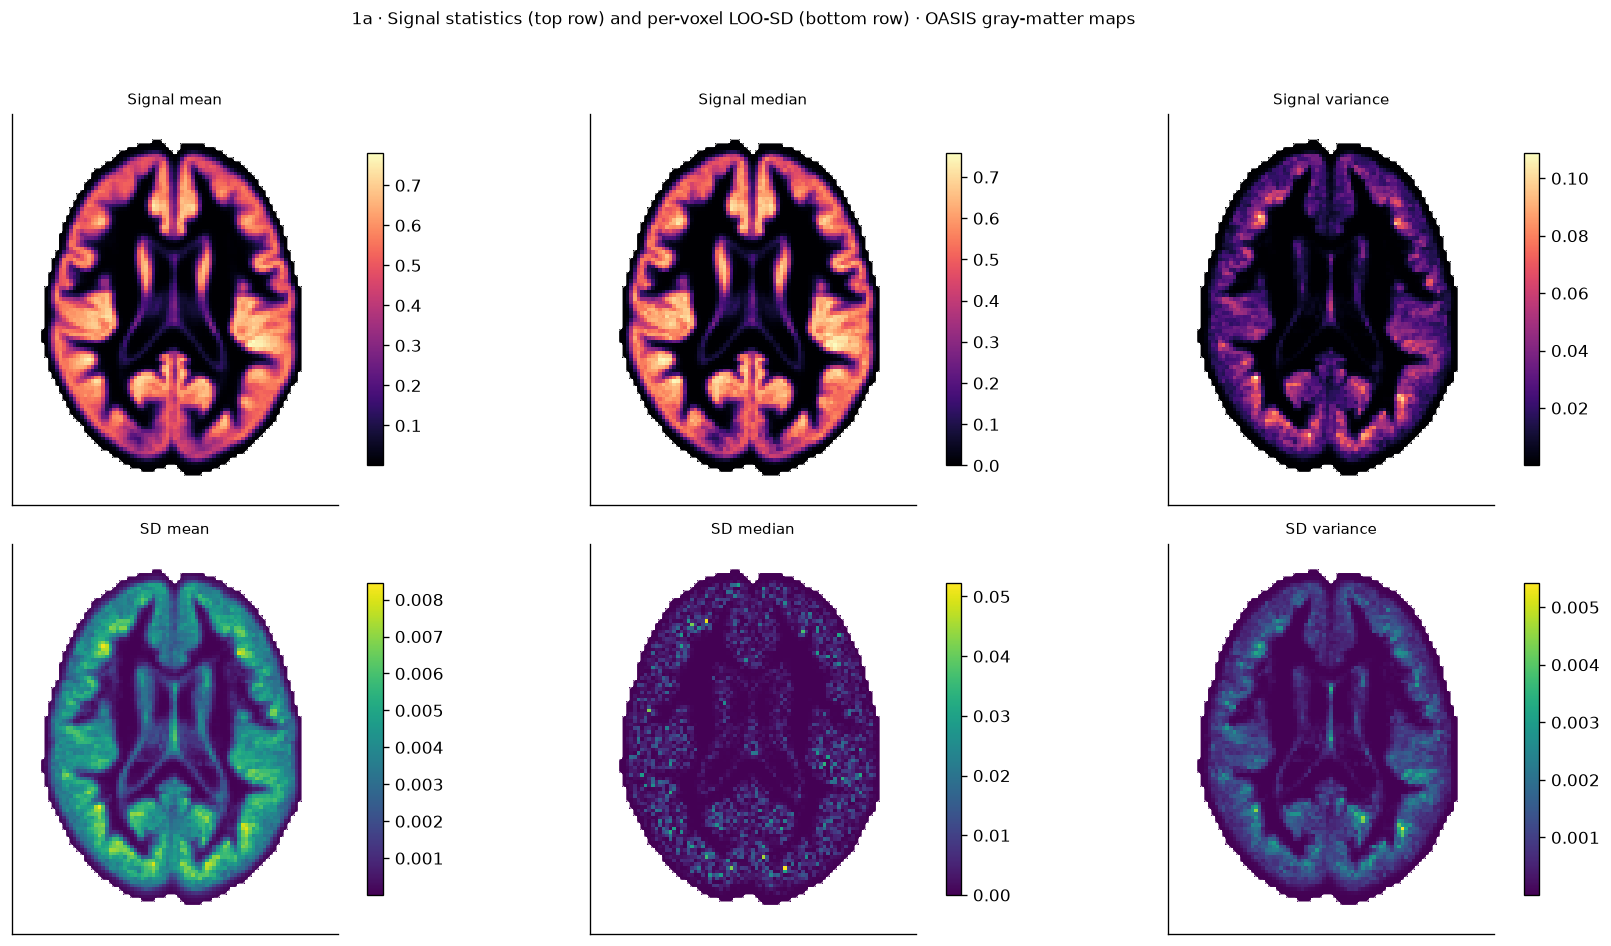

READ-OFF 1a: mean: signal span 0.877, median noise-scale(SD) 0.00266 | median: signal span 0.904, median noise-scale(SD) 0.00127 | variance: signal span 0.174, median noise-scale(SD) 0.000406


In [6]:
# Figure 1a — two rows, three columns:
# top: signal mean, median, variance; bottom: corresponding per-voxel LOO-SD
vols0 = COHORT[0]

sig = {
    "mean": vols0.mean(0),
    "median": np.median(vols0, 0),
    "variance": vols0.var(0),
}

sd = {}
for st in STATS:
    _, D, _ = ph.loo_artifacts(vols0, PIPES[st])
    sd[st] = D.std(0)  # per-voxel LOO-perturbation SD

panels = [
    ("Signal mean", sig["mean"], CMAP_MAG),
    ("Signal median", sig["median"], CMAP_MAG),
    ("Signal variance", sig["variance"], CMAP_MAG),
    ("SD mean", sd["mean"], CMAP_CNT),
    ("SD median", sd["median"], CMAP_CNT),
    ("SD variance", sd["variance"], CMAP_CNT),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for a, (ttl, m, cmap) in zip(axes.flat, panels):
    im = show(
        a,
        np.where(MASK, m, np.nan)[:, :, zc].T,
        cmap,
        outline=MASK_AX,
    )
    a.set_title(ttl, fontsize=9)
    fig.colorbar(im, ax=a, shrink=0.8)

fig.suptitle(
    f"1a · Signal statistics (top row) and per-voxel LOO-SD (bottom row)"
    f" · {SUBSTRATE}",
    fontsize=10,
)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("READ-OFF 1a: " + " | ".join(
    f"{st}: signal span {np.ptp(sig[st][MASK]):.3g}, "
    f"median noise-scale(SD) {np.median(sd[st][MASK]):.3g}"
    for st in STATS
))

## 2 · Tiling geometry

How patches cover the brain at each overlap, and how many pile up on each voxel. Overlap is set by
stride: `stride = round(patch·(1−overlap))`, floored at 1, with the last start anchored to the
volume edge so coverage reaches the far side. **The patch count quoted in each panel below is the
TOTAL number of patches tiled at that setting** (not a per-voxel number); the per-voxel count — how
many patches cover a given voxel — is the separate *coverage-multiplicity* map in Figure 2b.

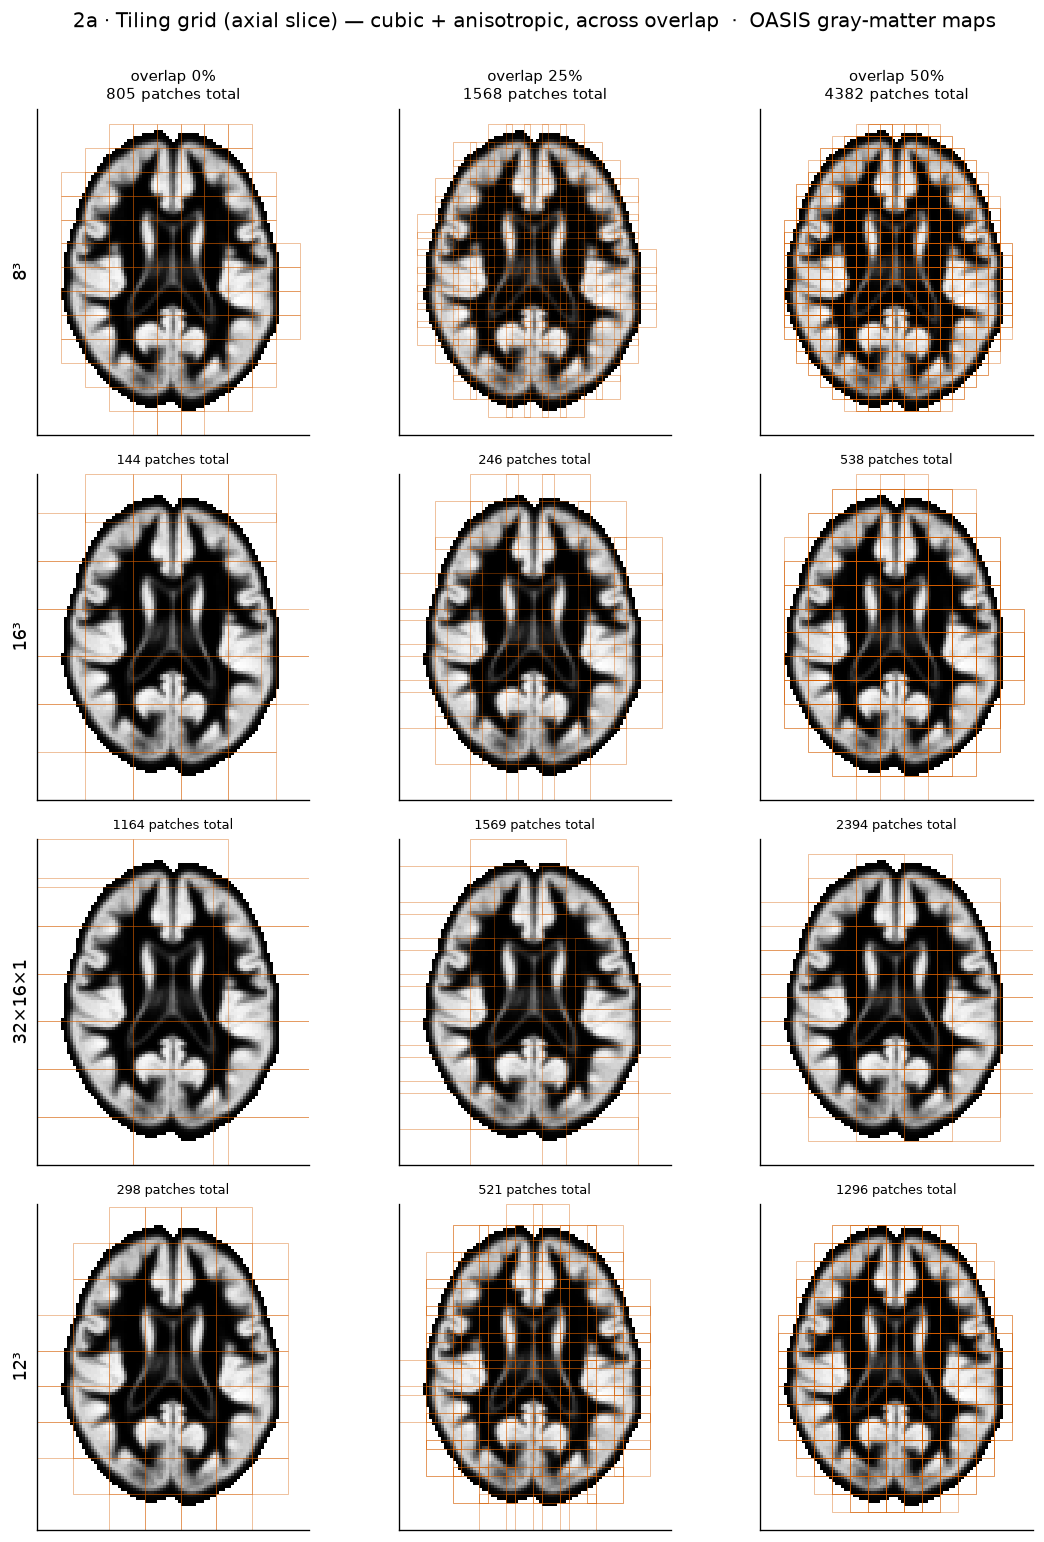

In [8]:
# Figure 2a — tiling grid on one axial slice: 4³ (cubic) and the two anisotropic shapes, across overlap
# up to 5 configured shapes (cubic + anisotropic), robust to SHAPES changes
show_shapes = [n for n in ["3x3x3","4x4x4","8x8x8","16x16x16","8x8x1","32x16x1","12x12x12"] if n in SHAPES][:5]
fig, axes = plt.subplots(len(show_shapes), len(OVERLAPS), figsize=(3.2*len(OVERLAPS), 3.2*len(show_shapes)))
for i, nm in enumerate(show_shapes):
    ps = SHAPES[nm]
    for j, o in enumerate(OVERLAPS):
        boxes, fr, stride = T.tile_boxes(VOLSHAPE, ps, o, MASK, MIN_FRAC)
        show(axes[i,j], np.where(MASK, COHORT[0].mean(0), np.nan)[:,:,zc].T, "Greys_r")
        for (x0,y0,z0) in boxes:
            if z0 <= zc < z0+ps[2]:
                axes[i,j].add_patch(plt.Rectangle((x0-0.5,y0-0.5), ps[0], ps[1], fill=False,
                                                  edgecolor="#D55E00", lw=0.45, alpha=0.5))
        if i==0: axes[i,j].set_title(f"overlap {int(o*100)}%\n{len(boxes)} patches total", fontsize=9)
        else:    axes[i,j].set_title(f"{len(boxes)} patches total", fontsize=8)
        if j==0: axes[i,j].set_ylabel(DISP[nm], fontsize=11)
fig.suptitle(f"2a · Tiling grid (axial slice) — cubic + anisotropic, across overlap  ·  {SUBSTRATE}", y=1.0)
plt.tight_layout(); plt.show()

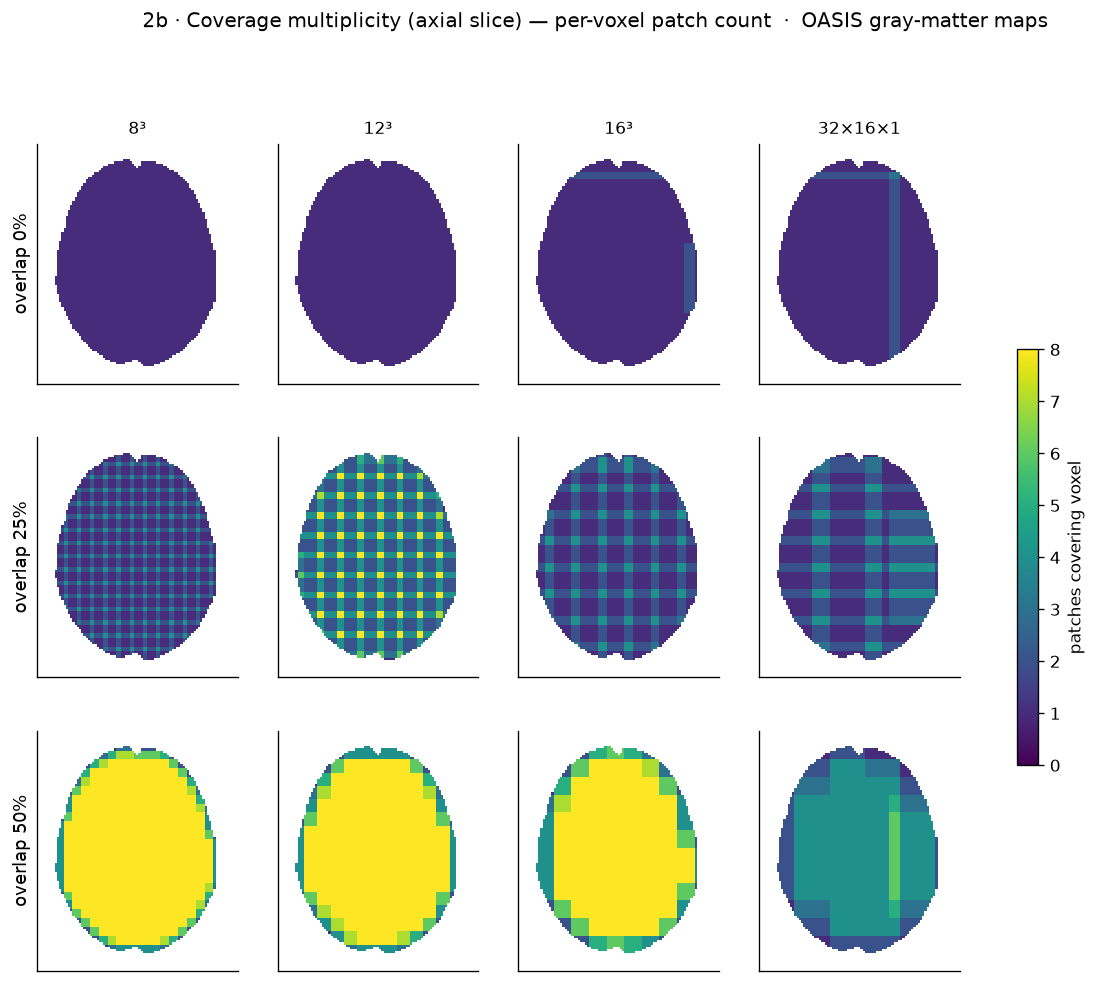

In [9]:
# Figure 2b — coverage multiplicity (rows=overlap, cols=shape)
fig, axes = plt.subplots(
    len(OVERLAPS), len(SHAPES),
    figsize=(3.1 * len(SHAPES), 3.0 * len(OVERLAPS)),
    squeeze=False
)

mult_store = {}
vmax_m = 0

for nm, ps in SHAPES.items():
    for o in OVERLAPS:
        boxes, fr, stride = T.tile_boxes(VOLSHAPE, ps, o, MASK, MIN_FRAC)
        mult = np.zeros(VOLSHAPE)
        for x0, y0, z0 in boxes:
            mult[x0:x0+ps[0], y0:y0+ps[1], z0:z0+ps[2]] += (
                MASK[x0:x0+ps[0], y0:y0+ps[1], z0:z0+ps[2]]
            )
        mult_store[(nm, o)] = mult
        vmax_m = max(vmax_m, np.percentile(mult[MASK], 99))

for i, o in enumerate(OVERLAPS):
    for j, nm in enumerate(SHAPES):
        im = show(
            axes[i, j],
            np.where(MASK, mult_store[(nm, o)], np.nan)[:, :, zc].T,
            CMAP_CNT, vmin=0, vmax=vmax_m
        )
        if i == 0:
            axes[i, j].set_title(DISP[nm], fontsize=10)
        if j == 0:
            axes[i, j].set_ylabel(f"overlap {int(o*100)}%", fontsize=11)

fig.colorbar(im, ax=axes, shrink=0.5, label="patches covering voxel")
fig.suptitle(
    f"2b · Coverage multiplicity (axial slice) — per-voxel patch count  ·  {SUBSTRATE}",
    y=1.0
)
plt.show()

**How can one voxel sit under as many as 12 patches? (in plain words.)** Take one axis at a time. With **no
overlap** the patches sit side by side, so a voxel is in exactly **1** patch. At **50% overlap** each patch
starts halfway into the previous one, so a voxel is caught by **2** patches along that axis. In 3-D the axes
multiply: `2 × 2 × 2 = ` **8** patches on a typical **interior** voxel. The extra ones (up to **12**) appear
only near the **brain's edge**: to guarantee the last slice is covered, the final patch on each axis is pushed
back to touch the edge, so it overlaps its neighbour more than usual and a **third** patch can reach that voxel
on one axis (`3 × 2 × 2 = ` **12**). So the counts are **1** with no overlap, **8** in the interior at 50%
overlap, and **up to 12** right at the boundary — not "6, one per face".

In [36]:
# If needed, run once:
# %pip install numpy plotly nbformat

import itertools
import numpy as np
import plotly.graph_objects as go

# ── Parameters ────────────────────────────────────────────────────────
VOLUME_SHAPE = (48, 48, 48)   # voxels along x, y, z
PATCH_SIZE = (16, 16, 16)     # rectangular patches are supported
OVERLAP = 0.50               # fraction: 0.25 = 25%; or (0.25, 0.50, 0.75)
VOXEL = (24, 24, 24)         # zero-based voxel index; try (0, 24, 24)
ADD_BOUNDARY_PATCHES = False # append final patch to reach each volume boundary
SHOW_WHOLE_VOLUME = False    # False: zoom to patches covering the voxel
# ──────────────────────────────────────────────────────────────────────

shape = np.asarray(VOLUME_SHAPE, dtype=int)
size = np.asarray(PATCH_SIZE, dtype=int)
voxel = np.asarray(VOXEL, dtype=int)
overlap = np.broadcast_to(np.asarray(OVERLAP, dtype=float), (3,))

if any(a.shape != (3,) for a in (shape, size, voxel)):
    raise ValueError("Volume shape, patch size, and voxel must have 3 entries.")
if np.any(size < 1) or np.any(size > shape):
    raise ValueError("Patch dimensions must be between 1 and the volume size.")
if np.any(voxel < 0) or np.any(voxel >= shape):
    raise ValueError("VOXEL must lie inside the volume.")
if np.any(~np.isfinite(overlap)) or np.any((overlap < 0) | (overlap >= 1)):
    raise ValueError("Overlap must be between 0 (inclusive) and 1 (exclusive).")

# Integer strides: nearest integer, with a minimum of one voxel.
stride = np.maximum(1, np.floor(size * (1 - overlap) + 0.5).astype(int))
actual_overlap = 1 - stride / size

def axis_starts(length, patch, step):
    """Regular grid, optionally with an extra boundary-aligned patch."""
    starts = list(range(0, length - patch + 1, step))
    if ADD_BOUNDARY_PATCHES and starts[-1] != length - patch:
        starts.append(length - patch)
    return starts

starts = [
    axis_starts(int(n), int(p), int(s))
    for n, p, s in zip(shape, size, stride)
]

# Half-open intervals match Python slicing: start <= voxel < start + size.
covering_starts = [
    [s for s in axis if s <= v < s + p]
    for axis, v, p in zip(starts, voxel, size)
]
patches = [
    np.asarray(origin, dtype=int)
    for origin in itertools.product(*covering_starts)
]

print(f"Stride: {tuple(stride)} voxels")
print("Actual overlap: " + ", ".join(
    f"{axis}={100 * value:.1f}%"
    for axis, value in zip("xyz", actual_overlap)
))
counts = [len(axis) for axis in covering_starts]
print(
    f"Coverage at {tuple(voxel)}: "
    f"{counts[0]} × {counts[1]} × {counts[2]} = {len(patches)} patches"
)
print(f"Total patches in volume: {np.prod([len(a) for a in starts]):,}")

# Coordinates represent voxel boundaries; the marked voxel is at its centre.
corners = np.array(list(itertools.product((0, 1), repeat=3)))
edges = [
    (i, j)
    for i in range(8)
    for j in range(i + 1, 8)
    if np.count_nonzero(corners[i] != corners[j]) == 1
]

def box_lines(origin, dimensions):
    vertices = np.asarray(origin) + corners * np.asarray(dimensions)
    xyz = [[], [], []]
    for i, j in edges:
        for axis in range(3):
            xyz[axis].extend([
                float(vertices[i, axis]),
                float(vertices[j, axis]),
                None,
            ])
    return xyz

def line_trace(xyz, color, width, **kwargs):
    return go.Scatter3d(
        x=xyz[0], y=xyz[1], z=xyz[2],
        mode="lines",
        line=dict(color=color, width=width),
        showlegend=False,
        **kwargs,
    )

fig = go.Figure()

# All covering patches remain visible as faint context.
context = [[], [], []]
for origin in patches:
    lines = box_lines(origin, size)
    for axis in range(3):
        context[axis].extend(lines[axis])

fig.add_trace(line_trace(
    context, "rgba(130,140,155,0.30)", 3,
    hoverinfo="skip",
))

# One selectable highlighted outline per covering patch.
for i, origin in enumerate(patches):
    fig.add_trace(line_trace(
        box_lines(origin, size), "#36a9e1", 7,
        visible=(i == 0),
        hovertemplate=(
            f"Patch {i + 1}<br>"
            f"Start: {tuple(origin)}<br>"
            f"Stop: {tuple(origin + size)} (exclusive)"
            "<extra></extra>"
        ),
    ))

point = voxel + 0.5
fig.add_trace(go.Scatter3d(
    x=[point[0]], y=[point[1]], z=[point[2]],
    mode="markers+text",
    marker=dict(size=6, color="#ef8354"),
    text=["Selected voxel"],
    textposition="top center",
    hovertemplate=f"Voxel index: {tuple(voxel)}<extra></extra>",
    showlegend=False,
))

# Dropdown updates visibility without resetting the camera.
buttons = [
    dict(
        label="All outlines",
        method="restyle",
        args=[{"visible": [True] + [False] * len(patches) + [True]}],
    )
]
for i, origin in enumerate(patches):
    buttons.append(dict(
        label=f"Patch {i + 1}: {tuple(origin)}",
        method="restyle",
        args=[{
            "visible": (
                [True]
                + [j == i for j in range(len(patches))]
                + [True]
            )
        }],
    ))

if SHOW_WHOLE_VOLUME or not patches:
    lower, upper = np.zeros(3), shape.astype(float)
else:
    lower = np.min(patches, axis=0).astype(float)
    upper = np.max(np.asarray(patches) + size, axis=0).astype(float)

padding = np.maximum((upper - lower) * 0.08, 1)
axis_settings = {
    axis: dict(
        title=f"{axis[0]} (voxel coordinates)",
        range=[lower[i] - padding[i], upper[i] + padding[i]],
    )
    for i, axis in enumerate(("xaxis", "yaxis", "zaxis"))
}

fig.update_layout(
    template="plotly_dark",
    height=650,
    title=f"{len(patches)} patches covering voxel {tuple(voxel)}",
    margin=dict(l=0, r=0, b=0, t=110),
    scene=dict(
        **axis_settings,
        aspectmode="data",
        dragmode="orbit",
        camera=dict(projection=dict(type="orthographic")),
        uirevision="keep-camera",
    ),
    updatemenus=[dict(
        buttons=buttons,
        active=1 if patches else 0,
        direction="down",
        x=0, y=1.12,
        xanchor="left", yanchor="top",
    )],
)

fig.show(config={"scrollZoom": True, "displaylogo": False})

Stride: (np.int64(8), np.int64(8), np.int64(8)) voxels
Actual overlap: x=50.0%, y=50.0%, z=50.0%
Coverage at (np.int64(24), np.int64(24), np.int64(24)): 2 × 2 × 2 = 8 patches
Total patches in volume: 125


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

**Tiling on all three anatomical planes.** The same patch configuration shown on an axial, coronal, and sagittal slice, with the brain mask outline, so the 3-D distribution of patches is visible (2b above shows only the axial multiplicity). Orange lines mark patch-start boundaries.

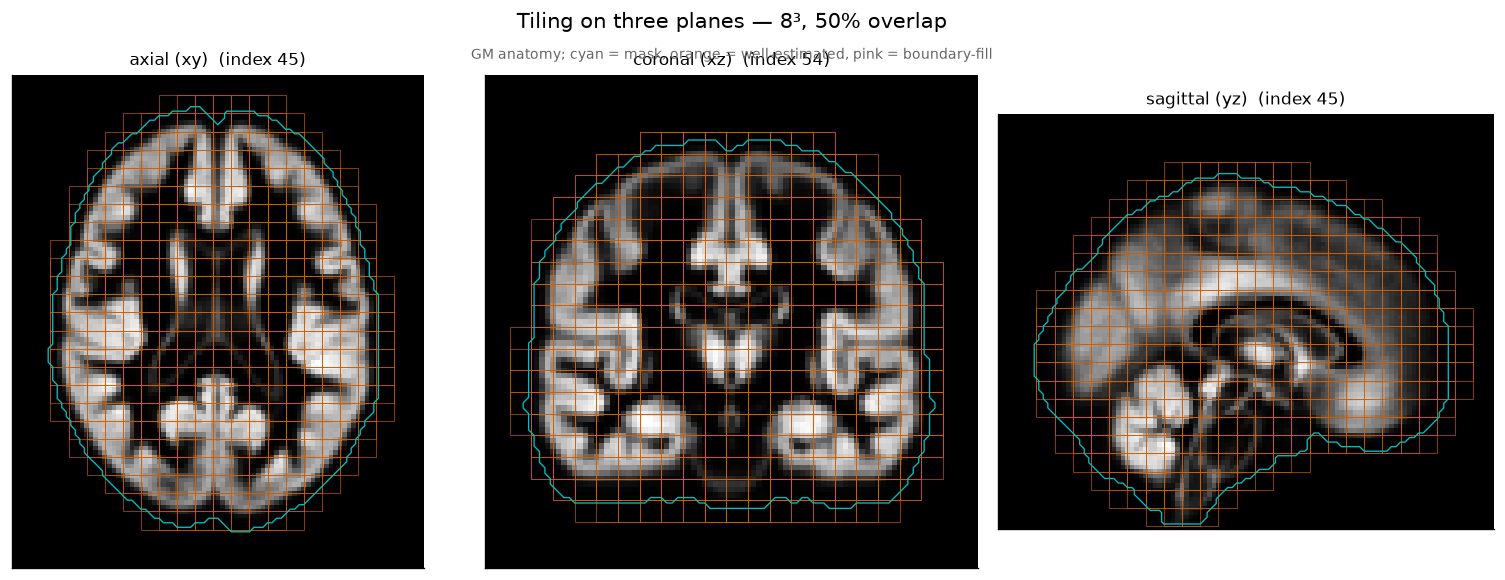

In [10]:
# three-plane tiling on GM ANATOMY with the REAL, mask-restricted patches (items 1,7).
# The tiling covers the MASK, not the whole volume: tile_boxes keeps patches >=min_frac in-brain
# (orange) plus boundary-fill patches (pink); patches fully outside the brain are never created.
import matplotlib.patches as mpatches
def plot_tiling_planes(ps, ovl, main, sub=None, anat=_mean_anat):
    boxes, fracs, stride = T.tile_boxes(VOLSHAPE, ps, ovl, MASK, MIN_FRAC, cover=COVER_HOLES)
    cx, cy, cz = VOLSHAPE[0]//2, VOLSHAPE[1]//2, VOLSHAPE[2]//2
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
    for ax, (nmp, axis, idx, da, db) in zip(axes, [
            ("axial (xy)", 2, cz, 0, 1), ("coronal (xz)", 1, cy, 0, 2), ("sagittal (yz)", 0, cx, 1, 2)]):
        if   axis == 2: bg = anat[:, :, idx].T; mk = MASK[:, :, idx].T
        elif axis == 1: bg = anat[:, idx, :].T; mk = MASK[:, idx, :].T
        else:           bg = anat[idx, :, :].T; mk = MASK[idx, :, :].T
        ax.imshow(bg, origin="lower", cmap="gray", interpolation="nearest")
        ax.contour(mk, levels=[0.5], colors="#00BFC4", linewidths=0.8)
        # draw the layer of real patches whose out-of-plane centre sits near this slice (legible count)
        for (x0, y0, z0), fr in zip(boxes, fracs):
            o = (x0, y0, z0); cen = o[axis] + ps[axis] / 2.0
            if abs(cen - idx) <= max(stride[axis] / 2.0, 0.5):
                col = "#D55E00" if fr >= MIN_FRAC else "#CC79A7"
                ax.add_patch(mpatches.Rectangle((o[da], o[db]), ps[da], ps[db],
                                                fill=False, edgecolor=col, lw=0.5, alpha=0.75))
        ax.set_title(f"{nmp}  (index {idx})", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); dualtitle(fig, main, sub, y_main=1.04, y_sub=0.975); plt.show()

_tp_name = "8x8x8" if "8x8x8" in SHAPES else list(SHAPES)[0]
plot_tiling_planes(SHAPES[_tp_name], 0.5,
    f"Tiling on three planes — {DISP[_tp_name]}, 50% overlap",
    "GM anatomy; cyan = mask, orange = well-estimated, pink = boundary-fill")

**Patch count vs overlap.** Total patches on a log axis, one line per shape. The key non-obvious
feature is the stride rounding: at a given overlap, `stride = round(patch·(1−overlap))`, so at 75%
overlap 4³ rounds to stride 1 (it tiles every voxel → a huge count), while 6³→round(1.5)=2 and
8³→round(2.0)=2 both land on stride 2 and so stay close to each other. The large gap is 4³ vs the
rest, not 6³ vs 8³.

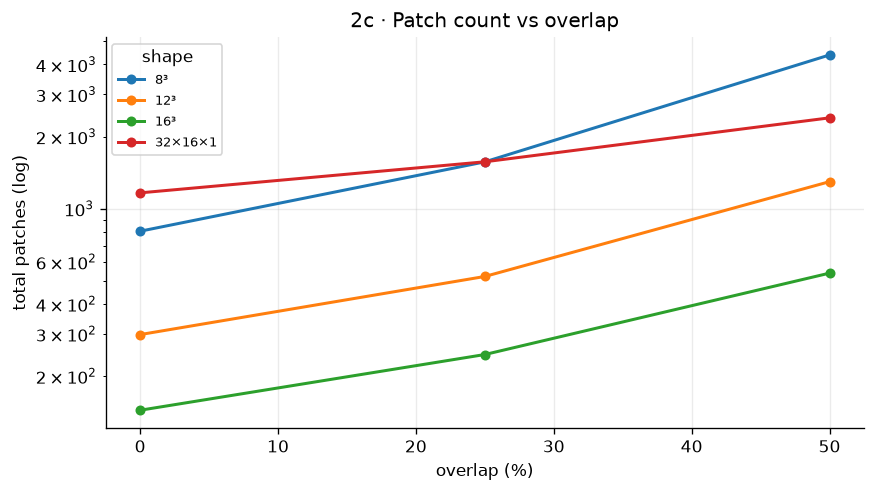

READ-OFF 2c: strides at 75% overlap — 8³->2, 12³->3, 16³->4. stride=round(patch*0.25): a side-4 patch rounds to 1 (tiles every voxel -> count explodes),
while larger sides keep stride>=2 and stay far cheaper.


In [11]:
fig, ax = plt.subplots(figsize=(7.4, 4.2))
for nm, ps in SHAPES.items():
    cnts = [len(T.tile_boxes(VOLSHAPE, ps, o, MASK, MIN_FRAC)[0]) for o in OVERLAPS]
    ax.plot([int(o*100) for o in OVERLAPS], cnts, "o-", lw=1.8, ms=5, label=DISP[nm])
ax.set_yscale("log"); ax.set_xlabel("overlap (%)"); ax.set_ylabel("total patches (log)")
ax.set_title("2c · Patch count vs overlap"); ax.legend(fontsize=8, title="shape")
plt.tight_layout(); plt.show()
# stride at 75% overlap for the cubic shapes present (robust to the configured SHAPES)
_cubic = [n for n in SHAPES if len(set(SHAPES[n]))==1]
s75 = {nm: T.stride_from_overlap(SHAPES[nm], 0.75)[0] for nm in _cubic}
print("READ-OFF 2c: strides at 75% overlap — " +
      ", ".join(f"{DISP[nm]}->{s75[nm]}" for nm in _cubic) +
      ". stride=round(patch*0.25): a side-4 patch rounds to 1 (tiles every voxel -> count explodes),\n"
      "while larger sides keep stride>=2 and stay far cheaper.")

## 3 · Overlap aggregation — combining overlapping patch noise

When patches overlap, each voxel has several independent noise proposals and we must combine them.
Four rules are compared:

- **sum** — just add all contributions. Magnitude grows wherever patches pile up.
- **plain average** — divide by the coverage count. Averaging k independent draws shrinks noise by
  1/√k, *unevenly* (edges keep full noise, interiors are suppressed) → blotchy, with seams.
- **partition-of-unity (POU)** — tapered (Hann) weights summing to 1 per voxel: patches fade in/out
  at their borders so seams vanish; still shrinks variance (by Σwᵢ²), but smoothly.
- **energy-preserving POU** — same taper, divide by √(Σwᵢ²): smooth seams **and** noise held at full
  designed strength. This is the one carried into the privacy eval.

The figure below shows, for one configuration, (row 1) the four assembled fields, (row 2) plain
average minus each POU version so the size and location of the difference are visible, and (row 3)
the **magnitude** |noise| for two blends next to the sensitivity field — bright regions in |noise|
should track bright regions in sensitivity, i.e. the most protected regions.

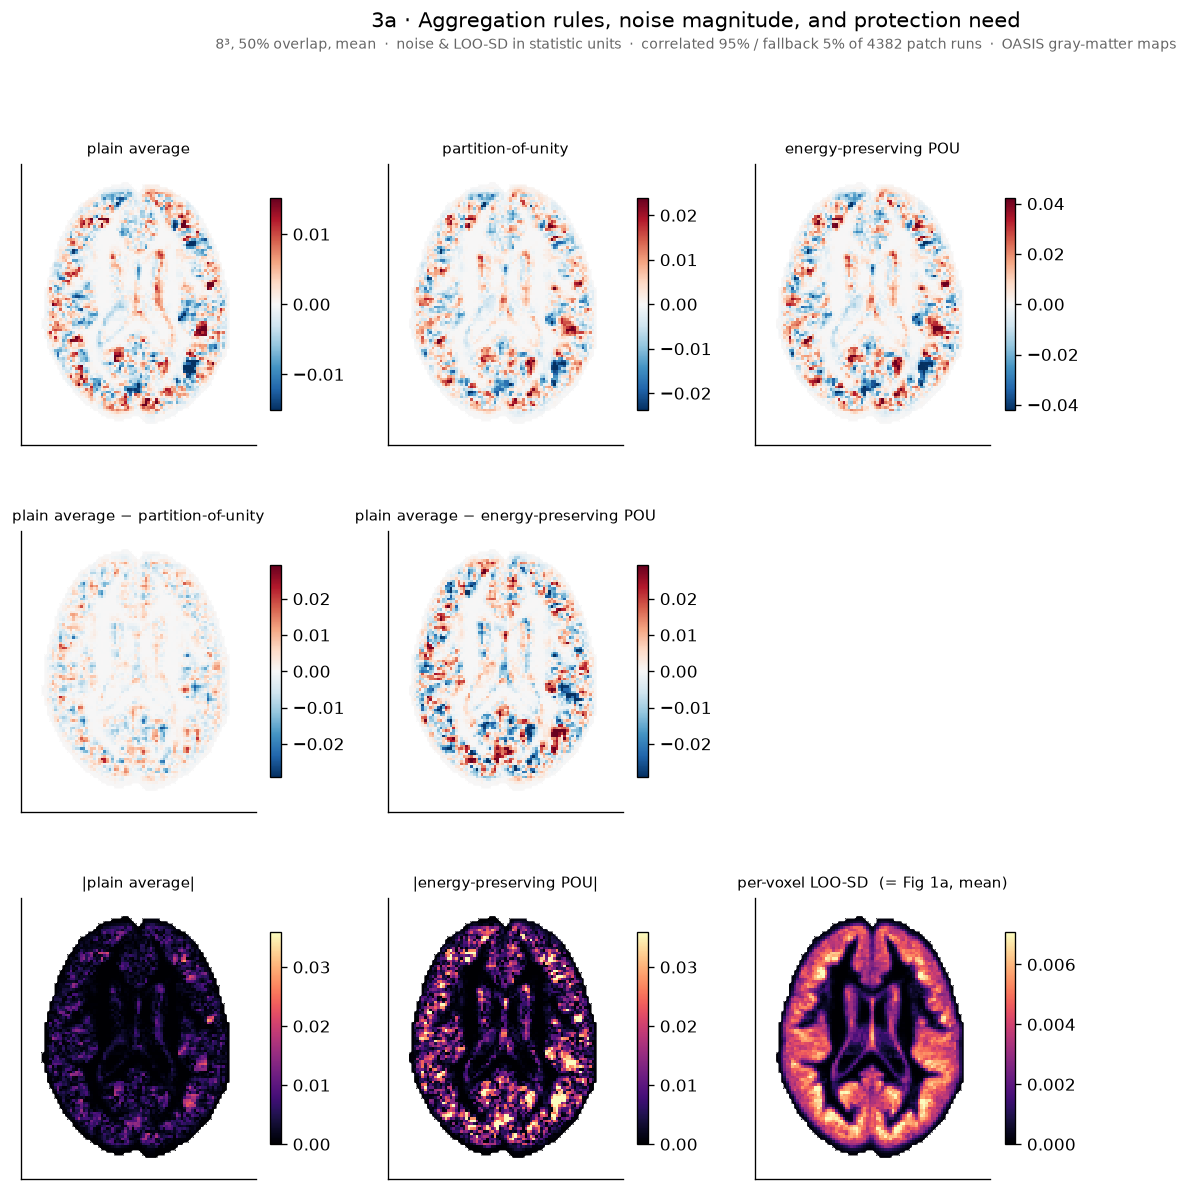

READ-OFF 3a: the LOO-SD map here is the SAME quantity as Fig 1a's SD-mean panel (per-voxel std across subjects of the signed LOO perturbations). corr(|energy-POU noise|, LOO-SD) = 0.64 — noise magnitude tracks local LOO-SD, as the mechanism scales per-mode noise to the patch covariance.
           noise composition at this config: 95% of the 4382 patch runs drew accepted CORRELATED noise, 5% fell back (tail-filled unmet modes). A fallback patch is still bar-satisfying; only its unmet modes are tail-sampled. Small patches fall back more (see 4e).


In [12]:
# compute demo assembles once for §3 (reused across its figures): all statistics at 4³, 50%
demo_shape, demo_ovl = "8x8x8", 0.5
R3 = {st: A_FIELD(COHORT[0], MASK, st, SHAPES[demo_shape], demo_ovl,
                           epsilon=EPSILON, base_seed=0, min_frac=MIN_FRAC, n_jobs=NJOBS, mech_kind=MECH_KIND) for st in STATS}
_, Dm, _ = ph.loo_artifacts(COHORT[0], PIPES["mean"]); SENS = Dm.std(0)      # mean sensitivity field

F = R3["mean"]["fields"]
fig = plt.figure(figsize=(15, 11)); gs = gridspec.GridSpec(3, 4, figure=fig, hspace=0.3, wspace=0.25)
# row 1: the RELEASE blends (sum removed per item 4 -- it only rescales and misleads on range)
_blends_show = ["average", "pou", "pou_energy"]
for k, b in enumerate(_blends_show):
    ax = fig.add_subplot(gs[0, k]); vmn, vmx = robust_sym(F[b][MASK])
    im = show(ax, np.where(MASK, F[b], np.nan)[:,:,zc].T, CMAP_DIV, vmin=vmn, vmax=vmx,
              title=BL_DISP[b], outline=MASK_AX); plt.colorbar(im, ax=ax, shrink=0.75)
# row 2: average - POU versions  (SHARED diverging scale across both, for comparability)
diffs = {b: F["average"] - F[b] for b in ["pou", "pou_energy"]}
dvmn, dvmx = robust_sym(np.concatenate([diffs[b][MASK] for b in diffs]))
for k, b in enumerate(["pou", "pou_energy"]):
    ax = fig.add_subplot(gs[1, k])
    im = show(ax, np.where(MASK, diffs[b], np.nan)[:,:,zc].T, CMAP_DIV, vmin=dvmn, vmax=dvmx,
              title=f"plain average − {BL_DISP[b]}", outline=MASK_AX); plt.colorbar(im, ax=ax, shrink=0.75)
# row 3: |noise| for two blends (SHARED magnitude scale) + sensitivity field (own scale: different units)
mag_noise = {"|plain average|": np.abs(F["average"]), "|energy-preserving POU|": np.abs(F["pou_energy"])}
nvmx = np.percentile(np.concatenate([v[MASK] for v in mag_noise.values()]), 99)
for k, (ttl, m) in enumerate(mag_noise.items()):
    ax = fig.add_subplot(gs[2, k])
    im = show(ax, np.where(MASK, m, np.nan)[:,:,zc].T, CMAP_MAG, vmin=0, vmax=nvmx,
              title=ttl, outline=MASK_AX); plt.colorbar(im, ax=ax, shrink=0.75)
ax = fig.add_subplot(gs[2, 2])
im = show(ax, np.where(MASK, SENS, np.nan)[:,:,zc].T, CMAP_MAG, vmin=0, vmax=np.percentile(SENS[MASK], 99),
          title="per-voxel LOO-SD  (= Fig 1a, mean)", outline=MASK_AX); plt.colorbar(im, ax=ax, shrink=0.75)
_fr3 = R3["mean"]["fallback_rate"]; _n3 = R3["mean"]["n_patches"]
dualtitle(fig, "3a · Aggregation rules, noise magnitude, and protection need",
          f"{DISP[demo_shape]}, 50% overlap, mean  ·  noise & LOO-SD in statistic units  ·  "
          f"correlated {1-_fr3:.0%} / fallback {_fr3:.0%} of {_n3} patch runs  ·  {SUBSTRATE}",
          y_main=0.995, y_sub=0.975)
plt.show()
r = np.corrcoef(np.abs(F["pou_energy"])[MASK], SENS[MASK])[0,1]
print(f"READ-OFF 3a: the LOO-SD map here is the SAME quantity as Fig 1a's SD-mean panel (per-voxel std "
      f"across subjects of the signed LOO perturbations). corr(|energy-POU noise|, LOO-SD) = {r:.2f} — "
      f"noise magnitude {'tracks' if r>0.3 else 'only weakly tracks'} local LOO-SD, as the mechanism scales "
      f"per-mode noise to the patch covariance.")
print(f"           noise composition at this config: {1-_fr3:.0%} of the {_n3} patch runs drew "
      f"accepted CORRELATED noise, {_fr3:.0%} fell back (tail-filled unmet modes). A fallback patch is "
      f"still bar-satisfying; only its unmet modes are tail-sampled. Small patches fall back more (see 4e).")

**Seams and magnitude, per statistic.** Two views of what the blends do, now for mean, median
and variance (one row each):

- **Left — line profile across seams.** The x-axis is position along one horizontal row of voxels
  through the brain (a 1-D cut); the y-axis is the noise value at each voxel for each blend. Two
  *separate* things vary here — do not read them as one. (i) **Continuity (smoothness):** plain
  average can show abrupt steps where neighbouring patches meet (seams; clearest at low overlap),
  while POU and energy-POU taper across borders so the curve is continuous — no jumps. (ii)
  **Amplitude:** energy-preserving POU keeps the *full* designed magnitude, so its peaks are the
  **largest** on the plot. Those larger peaks are preserved noise, not roughness — the curve is still
  continuous. So "smoother" here means *seamless*, not *smaller*: plain average is smaller but can
  jump; energy-POU is larger but never jumps.
- **Right — realized noise SD vs coverage multiplicity.** The x-axis is how many patches cover a
  voxel (multiplicity k); the y-axis is the standard deviation of the realized noise among voxels
  with that k. Plain average follows the 1/√k shrink (dotted reference); energy-preserving POU stays
  flat at the designed level — it does not lose magnitude as overlap piles up.

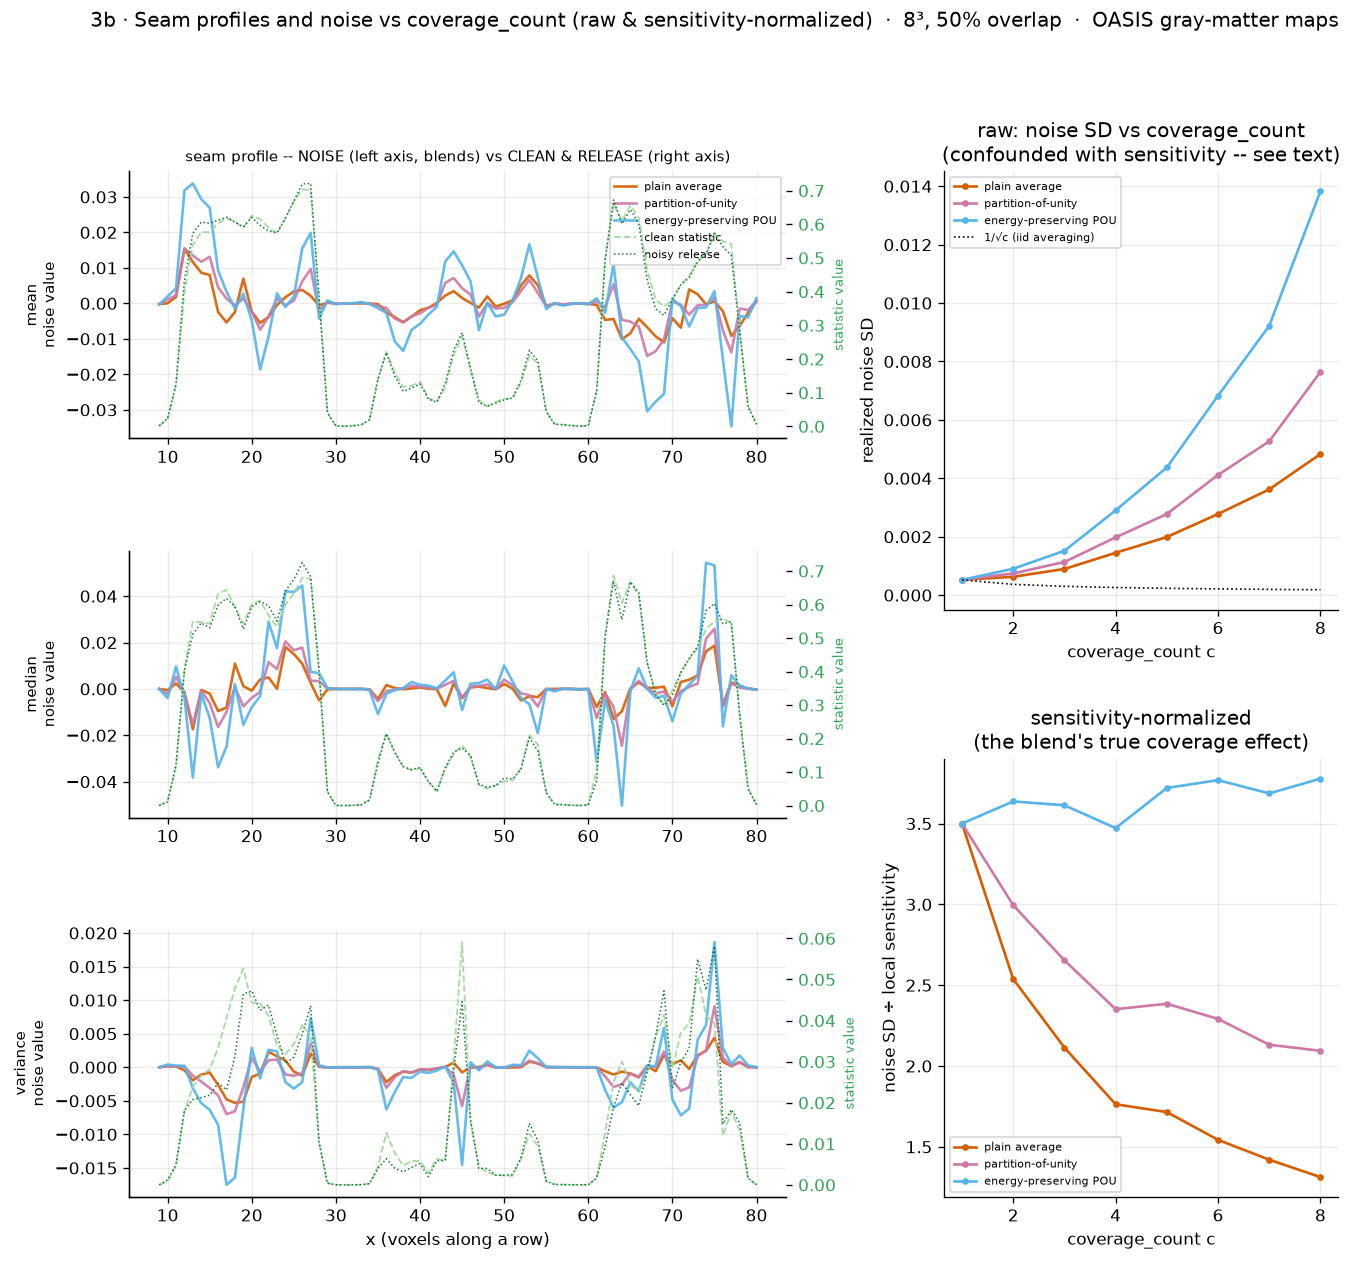

seam-roughness read-off (mean |Laplacian| of the noise field; lower seam/interior = smoother seams):
           plain average: seam 5.21e-03 | interior 9.87e-03 | ratio 0.53
      partition-of-unity: seam 7.54e-03 | interior 1.42e-02 | ratio 0.53
   energy-preserving POU: seam 1.23e-02 | interior 2.63e-02 | ratio 0.47
[note] the raw right panel rises with coverage mainly because coverage tracks sensitivity; the
       normalized panel isolates the blend: plain-average shrinks, energy-POU holds magnitude by design.


In [13]:
# 3b -- seam profiles (left) + coverage behaviour (right, TWO panels: raw and sensitivity-normalized).
# "coverage_count" (symbol c) = how many patches cover a voxel. We RESERVE k for eigenmodes.
#
# WHY TWO RIGHT-HAND PANELS: binning noise SD by coverage_count is confounded -- high-coverage voxels
# sit in the brain interior, which also has the HIGHEST local sensitivity, and the mechanism scales
# noise to sensitivity. So the raw curve mostly shows "we moved to a needier region", not the blend's
# averaging behaviour. Dividing each voxel's noise by its local sensitivity removes that confound and
# exposes the TRUE coverage effect (plain-average should shrink ~1/sqrt(c); energy-POU should hold).
fig = plt.figure(figsize=(13, 3.7*len(STATS)))
gs  = gridspec.GridSpec(len(STATS), 2, figure=fig, width_ratios=[2.0, 1.2], wspace=0.3, hspace=0.42)
row = VOLSHAPE[1]//2; xs = np.arange(VOLSHAPE[0]); inb = MASK[:, row, zc]
for i, st in enumerate(STATS):
    ax = fig.add_subplot(gs[i, 0]); Fs = R3[st]["fields"]; clean = R3[st]["clean"]
    for b in BLENDS_REL:                                   # NOISE value along the row (primary axis)
        prof = Fs[b][:, row, zc].copy(); prof[~inb] = np.nan
        lw = 1.6                                            # plain-average at standard width
        ax.plot(xs, prof, color=C_BLEND[b], lw=lw, alpha=0.9, label=BL_DISP[b])
    ax.set_ylabel(f"{st}\nnoise value", fontsize=9)
    axr = ax.twinx(); axr.grid(False)                      # CLEAN & RELEASE context: subtle, distinct style
    cp  = np.where(inb, clean[:, row, zc], np.nan)
    rel = np.where(inb, (clean + Fs["pou_energy"])[:, row, zc], np.nan)
    axr.plot(xs, cp,  color="#a1d99b", lw=1.1, ls="--", alpha=0.95, label="clean statistic")
    axr.plot(xs, rel, color="#006d2c", lw=0.9, ls=":",  alpha=0.95, label="noisy release")
    axr.set_ylabel("statistic value", fontsize=8, color="#31a354"); axr.tick_params(axis="y", labelcolor="#31a354")
    if i == 0:
        ax.set_title("seam profile -- NOISE (left axis, blends) vs CLEAN & RELEASE (right axis)", fontsize=9)
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = axr.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, fontsize=6.5, loc="upper right")
ax.set_xlabel("x (voxels along a row)")

# ---- right column: split into RAW (top) and SENSITIVITY-NORMALIZED (bottom) ----
gsr = gs[:, 1].subgridspec(2, 1, hspace=0.34)
ax_raw = fig.add_subplot(gsr[0]); ax_nrm = fig.add_subplot(gsr[1])
Fs = R3["mean"]["fields"]; mvals = R3["mean"]["mult"][MASK]
sens_b = SENS[MASK]; _ok = sens_b > (0.02 * np.median(sens_b[sens_b > 0]))   # guard tiny sensitivity
cs = np.arange(1, int(mvals.max()) + 1)
for b in BLENDS_REL:
    f = Fs[b][MASK]
    sd_c  = [f[np.isclose(mvals, c)].std() for c in cs]                       # raw SD per coverage_count
    fn = np.full_like(f, np.nan); fn[_ok] = f[_ok] / sens_b[_ok]
    sdn_c = [np.nanstd(fn[np.isclose(mvals, c)]) for c in cs]                 # SD of noise/sensitivity
    lw = 1.6
    ax_raw.plot(cs, sd_c,  "o-", color=C_BLEND[b], ms=3, lw=lw, label=BL_DISP[b])
    ax_nrm.plot(cs, sdn_c, "o-", color=C_BLEND[b], ms=3, lw=lw, label=BL_DISP[b])
base = Fs["average"][MASK]; s1 = base[np.isclose(mvals, 1)].std() if np.any(np.isclose(mvals, 1)) else np.nan
if np.isfinite(s1):
    ax_raw.plot(cs, s1/np.sqrt(cs), "k:", lw=1, label="1/√c (iid averaging)")
ax_raw.set(xlabel="coverage_count c", ylabel="realized noise SD",
           title="raw: noise SD vs coverage_count\n(confounded with sensitivity -- see text)")
ax_nrm.set(xlabel="coverage_count c", ylabel="noise SD ÷ local sensitivity",
           title="sensitivity-normalized\n(the blend's true coverage effect)")
ax_raw.legend(fontsize=6.5); ax_nrm.legend(fontsize=6.5)
fig.suptitle(f"3b · Seam profiles and noise vs coverage_count (raw & sensitivity-normalized)  ·  "
             f"{DISP[demo_shape]}, 50% overlap  ·  {SUBSTRATE}", y=1.0)
plt.show()

# ---- seam-roughness: a focused number for the "smoother seams" claim (item 5) ----
# roughness = mean |discrete Laplacian| of the noise field; compare SEAM voxels (coverage_count changes
# across a face) to interior voxels. A blend with smoother seams has a smaller seam/interior ratio.
from scipy import ndimage as _ndi
mult3 = R3["mean"]["mult"]
_grad = sum(np.abs(np.diff(mult3, axis=ax_, prepend=mult3.take([0], axis=ax_))) for ax_ in range(3))
seam = (MASK) & (_grad > 0); interior = (MASK) & (_grad == 0)
print("seam-roughness read-off (mean |Laplacian| of the noise field; lower seam/interior = smoother seams):")
for b in BLENDS_REL:
    lap = np.abs(_ndi.laplace(Fs[b]))
    rs = lap[seam].mean() if seam.any() else np.nan
    ri = lap[interior].mean() if interior.any() else np.nan
    print(f"  {BL_DISP[b]:>22}: seam {rs:.2e} | interior {ri:.2e} | ratio {rs/ri:.2f}")
print("[note] the raw right panel rises with coverage mainly because coverage tracks sensitivity; the\n"
      "       normalized panel isolates the blend: plain-average shrinks, energy-POU holds magnitude by design.")

## 4 · Noise field and utility

The main sweep: for every statistic × shape × overlap × seed we assemble the field (all blends share
the per-patch draws) and measure whole-brain utility against the clean statistic. Seed-0 fields and
per-patch ranks are cached for the maps here and in §5; utility is aggregated across seeds for 95%
CIs. The released error equals the noise field (noisy − clean = field), so the field maps *are* the
error maps.

**Border voxels — a fixed issue.** With a quality threshold `min_frac` alone, in-brain voxels near
the edge fall only under patches that are mostly outside the brain; those patches get dropped, and
the voxels would be released **with no noise** (a privacy hole). `tiling.tile_boxes` runs a second pass that
**greedily adds a near-minimal set** of boundary patches (fullest-first, each kept only if it covers a
still-uncovered in-brain voxel) until **every** in-brain voxel is covered. Covariance is still driven by
each patch's in-brain voxels (out-of-brain voxels are zero, so they contribute nothing). This is a greedy
cover, not a proven minimum. The cells below quantify the hole, show a schematic, and **validate** that the
fill pass does not distort the release (toggle `COVER_HOLES` in §0).

In [14]:
# Border-voxel coverage: uncovered in-brain voxels with the threshold alone vs with the coverage pass
rows = []
for nm, ps in SHAPES.items():
    b_no, _, _  = T.tile_boxes(VOLSHAPE, ps, 0.0, MASK, MIN_FRAC, cover=False)
    b_yes, _, _ = T.tile_boxes(VOLSHAPE, ps, 0.0, MASK, MIN_FRAC, cover=True)
    def uncov(boxes):
        cov = np.zeros(VOLSHAPE)
        for (x0,y0,z0) in boxes: cov[x0:x0+ps[0],y0:y0+ps[1],z0:z0+ps[2]] += MASK[x0:x0+ps[0],y0:y0+ps[1],z0:z0+ps[2]]
        return int(((cov==0)&MASK).sum())
    tot = int(MASK.sum())
    rows.append((DISP[nm], len(b_no), 100*uncov(b_no)/tot, len(b_yes), 100*uncov(b_yes)/tot))
cov_tbl = pd.DataFrame(rows, columns=["shape","patches(no cover)","% uncov(no cover)","patches(cover)","% uncov(cover)"])
print("Border coverage at 0% overlap (the worst case):\n")
print(cov_tbl.round(1).to_string(index=False))
print("\nREAD-OFF 4(border): the coverage pass drives uncovered in-brain voxels to 0 for every shape, "
      "at a modest patch-count increase; without it, large patches leave a substantial unprotected rim.")

Border coverage at 0% overlap (the worst case):

  shape  patches(no cover)  % uncov(no cover)  patches(cover)  % uncov(cover)
     8³                557                7.4             805             0.0
    12³                162               12.1             298             0.0
    16³                 65               18.0             144             0.0
32×16×1                563               22.1            1164             0.0

READ-OFF 4(border): the coverage pass drives uncovered in-brain voxels to 0 for every shape, at a modest patch-count increase; without it, large patches leave a substantial unprotected rim.


**Boundary-coverage: schematic and validation.** The schematic shows, on a 2-D toy brain, how the quality threshold leaves a rim of in-brain voxels uncovered and how the fill pass closes it. The validation then runs the real tiling with the fill pass **on vs off** and checks that it does not distort the release: rel-MSE on the region covered either way should be unchanged (fill touches only the rim), the fill-only voxels are exactly those that would otherwise be released with no noise, and their noise should be comparable to the interior (not degenerate).

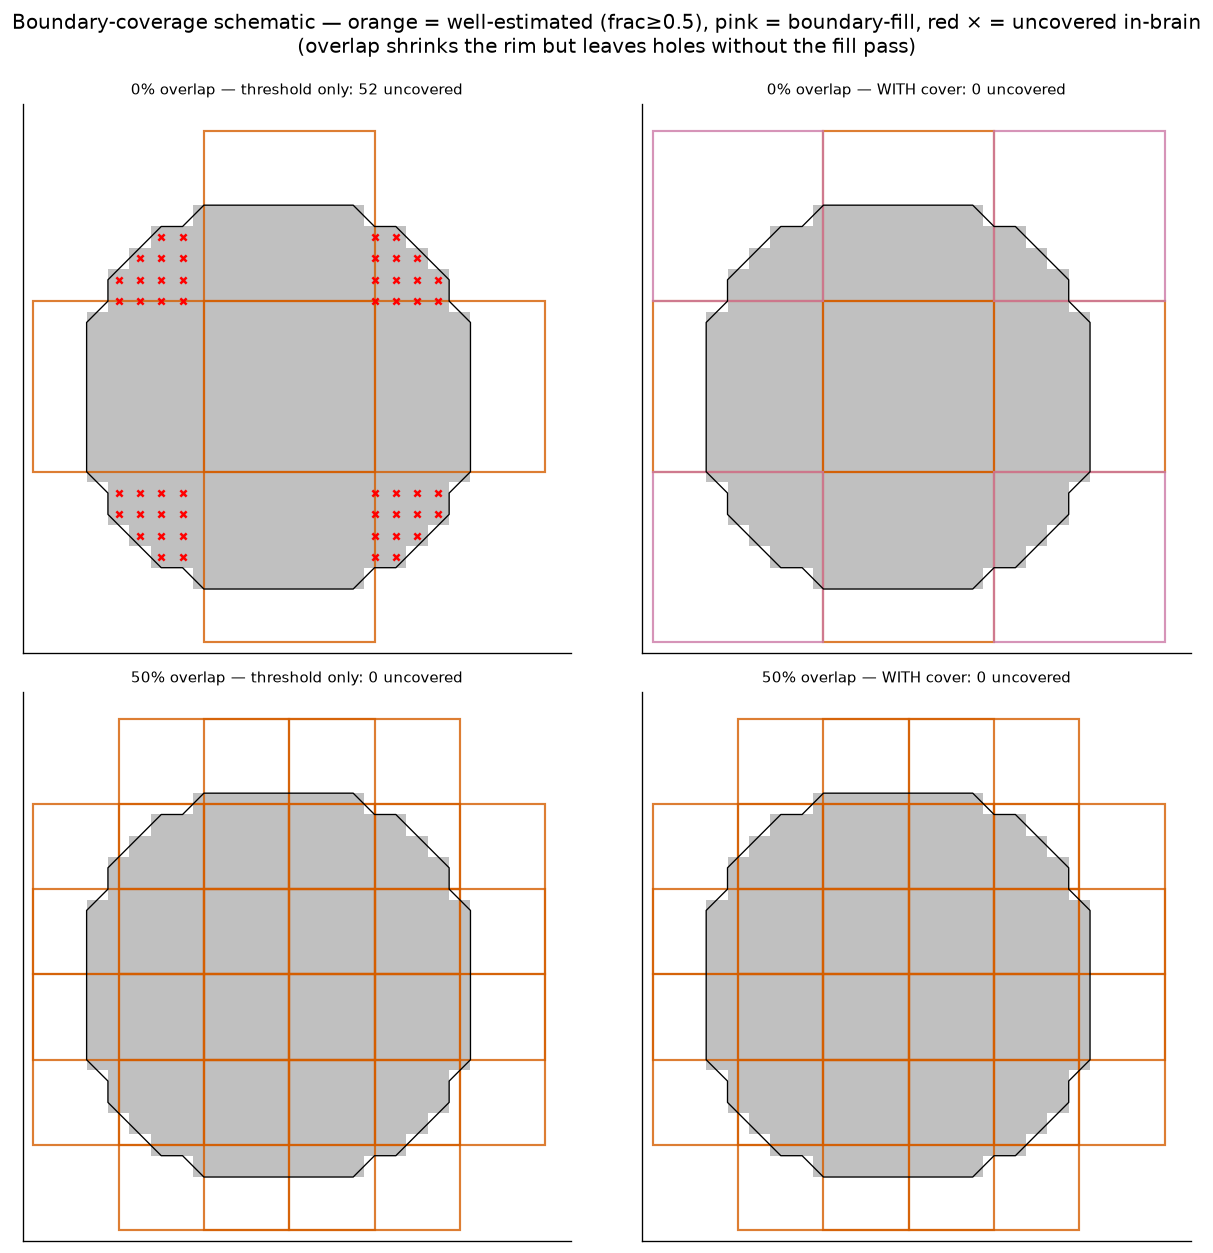

In [15]:
# 2-D schematic of the boundary-coverage pass -- shown WITHOUT and WITH patch overlap, so it
# matches the real tiling (overlap reduces, but does not eliminate, the uncovered rim).
import matplotlib.patches as mpatches
G = 24; yy, xx = np.mgrid[0:G, 0:G]; cc = (G-1)/2
brain2d = ((xx-cc)**2 + (yy-cc)**2) <= 9.5**2
ps2 = 8
f2 = lambda x0, y0: brain2d[y0:y0+ps2, x0:x0+ps2].mean()
def starts_for(stride):
    s = list(range(0, G-ps2+1, max(1, stride)))
    if s[-1] != G-ps2: s.append(G-ps2)
    return s
fig, axes = plt.subplots(2, 2, figsize=(10.5, 10.5))
for r, (ov_lab, stride) in enumerate([("0% overlap", ps2), ("50% overlap", ps2//2)]):
    starts = starts_for(stride)
    for c, cover in enumerate([False, True]):
        ax = axes[r, c]
        ax.imshow(brain2d, origin="lower", cmap="Greys", alpha=0.25)
        ax.contour(brain2d, levels=[0.5], colors="k", linewidths=0.8)
        covered = np.zeros((G, G), bool); kept = []
        for y0 in starts:
            for x0 in starts:
                if f2(x0, y0) >= 0.5:
                    kept.append((x0, y0, "keep")); covered[y0:y0+ps2, x0:x0+ps2] |= brain2d[y0:y0+ps2, x0:x0+ps2]
        if cover:
            for f, x0, y0 in sorted([(f2(x, y), x, y) for y in starts for x in starts if 0 < f2(x, y) < 0.5], reverse=True):
                sub = brain2d[y0:y0+ps2, x0:x0+ps2]
                if (sub & ~covered[y0:y0+ps2, x0:x0+ps2]).any():
                    kept.append((x0, y0, "fill")); covered[y0:y0+ps2, x0:x0+ps2] |= sub
        for x0, y0, kind in kept:
            ax.add_patch(mpatches.Rectangle((x0, y0), ps2, ps2, fill=False,
                                            edgecolor="#D55E00" if kind == "keep" else "#CC79A7", lw=1.3, alpha=0.8))
        hole = brain2d & ~covered; ys, xs = np.where(hole)
        ax.scatter(xs, ys, c="red", s=14, marker="x")
        ax.set_title(f"{ov_lab} — {'WITH cover' if cover else 'threshold only'}: {int(hole.sum())} uncovered",
                     fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Boundary-coverage schematic — orange = well-estimated (frac≥0.5), pink = boundary-fill, "
             "red × = uncovered in-brain\n(overlap shrinks the rim but leaves holes without the fill pass)", y=0.99)
plt.tight_layout(); plt.show()

overlap   shape  fill_only_%brain  relMSE_ON  relMSE_OFF  SD@fill  SD@interior
     0%      8³           7.41497    0.00122     0.00122  0.00505      0.01217
     0%     12³          12.11976    0.00117     0.00117  0.00727      0.01196
     0%     16³          18.02469    0.00103     0.00103  0.00932      0.01133
     0% 32×16×1          22.08433    0.00115     0.00114  0.01134      0.01218
    50%      8³           0.00247    0.00129     0.00129  0.00031      0.01383
    50%     12³           0.01972    0.00125     0.00125  0.00024      0.01346
    50%     16³           0.07994    0.00115     0.00115  0.00050      0.01256
    50% 32×16×1           0.92722    0.00119     0.00118  0.00183      0.01252


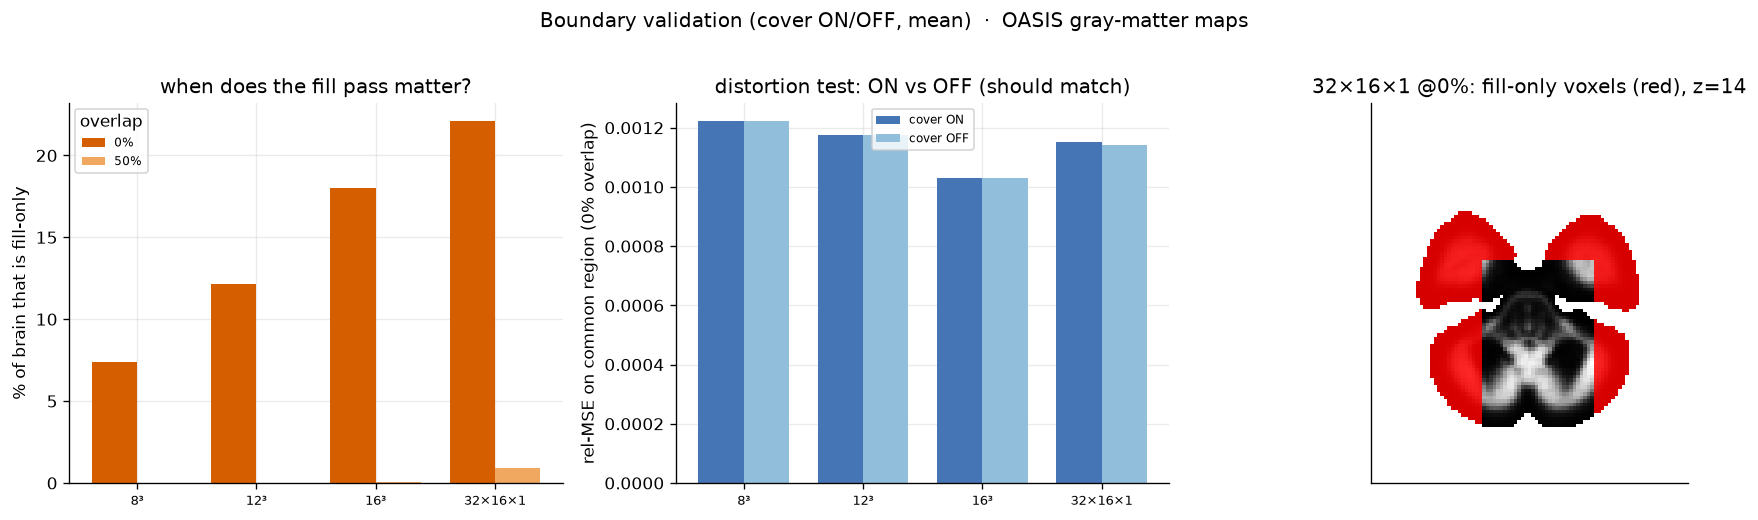

[read-off] Panel 2 is the distortion test: ON and OFF rel-MSE on the commonly-covered region coincide, so the fill pass does NOT change the bulk release -- it only adds noise to the rim voxels that would otherwise be released with no noise. Panel 1: the fill pass matters mainly at 0% overlap / large patches; at 50% overlap most shapes have few holes. SD@fill ≈ SD@interior in the table -> fill noise is not degenerate.


In [16]:
# boundary validation -- the key question: does the fill pass DISTORT the release? Run the real tiling
# with cover ON vs OFF, at both overlaps, and compare (a) how much brain is fill-only, (b) rel-MSE on the
# region covered either way (must match -> no distortion), (c) noise at fill-only vs interior.
_vst = "mean"
def _relmse(R, sel):
    c = R["clean"][sel]; n = (R["clean"] + R["fields"]["pou_energy"])[sel]
    return float(np.mean((n-c)**2) / (np.mean(c**2) + 1e-12))
rows = []; _best = (-1, None)
for ov in [0.0, 0.5]:
    for nm, ps in SHAPES.items():
        Ron  = A_FIELD(COHORT[0], MASK, _vst, ps, ov, base_seed=0, min_frac=MIN_FRAC, cover=True)
        Roff = A_FIELD(COHORT[0], MASK, _vst, ps, ov, base_seed=0, min_frac=MIN_FRAC, cover=False)
        con = Ron["mult"] > 0; coff = Roff["mult"] > 0
        fillonly = MASK & con & ~coff; common = MASK & con & coff
        f_on = Ron["fields"]["pou_energy"]; hi = Ron["mult"] >= np.median(Ron["mult"][MASK])
        rows.append({"overlap": f"{int(ov*100)}%", "shape": DISP[nm],
                     "fill_only_%brain": 100*fillonly.sum()/MASK.sum(),
                     "relMSE_ON": _relmse(Ron, common), "relMSE_OFF": _relmse(Roff, common),
                     "SD@fill": float(f_on[fillonly].std()) if fillonly.any() else np.nan,
                     "SD@interior": float(f_on[MASK & hi].std())})
        if ov == 0.0 and int(fillonly.sum()) > _best[0]:
            _best = (int(fillonly.sum()), (nm, fillonly, f_on, hi))
vdf = pd.DataFrame(rows)
print(vdf.round(5).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
# (1) how much brain is fill-only, per shape, at each overlap -- when does the fill pass matter?
import numpy as _np
shps = list(SHAPES); x = _np.arange(len(shps)); w = 0.38
for k, ov in enumerate(["0%", "50%"]):
    sub = vdf[vdf.overlap == ov].set_index("shape")
    ax[0].bar(x + (k-0.5)*w, [sub.loc[DISP[s], "fill_only_%brain"] for s in shps], w, label=ov,
              color=["#D55E00", "#f0a860"][k])
ax[0].set_xticks(x); ax[0].set_xticklabels([DISP[s] for s in shps], fontsize=8)
ax[0].set(ylabel="% of brain that is fill-only", title="when does the fill pass matter?"); ax[0].legend(title="overlap", fontsize=7)
# (2) THE distortion test: rel-MSE on the common region, ON vs OFF (bars must coincide)
sub0 = vdf[vdf.overlap == "0%"].set_index("shape")
ax[1].bar(x - w/2, [sub0.loc[DISP[s], "relMSE_ON"] for s in shps], w, label="cover ON", color="#4575b4")
ax[1].bar(x + w/2, [sub0.loc[DISP[s], "relMSE_OFF"] for s in shps], w, label="cover OFF", color="#91bfdb")
ax[1].set_xticks(x); ax[1].set_xticklabels([DISP[s] for s in shps], fontsize=8)
ax[1].set(ylabel="rel-MSE on common region (0% overlap)", title="distortion test: ON vs OFF (should match)"); ax[1].legend(fontsize=7)
# (3) where the fill-only voxels sit, for the shape with the most (0% overlap)
nm_b, fo_b, fon_b, hi_b = _best[1]
zsl = int(_np.argmax(fo_b.sum(axis=(0, 1)))) if fo_b.any() else zc
from matplotlib.colors import ListedColormap
ax[2].imshow(_np.where(MASK, _mean_anat, _np.nan)[:, :, zsl].T, origin="lower", cmap="gray")
ax[2].imshow(_np.where(fo_b[:, :, zsl].T, 1.0, _np.nan), origin="lower", cmap=ListedColormap(["red"]), vmin=0, vmax=1, alpha=0.85)
ax[2].set_title(f"{DISP[nm_b]} @0%: fill-only voxels (red), z={zsl}"); ax[2].set_xticks([]); ax[2].set_yticks([])
fig.suptitle(f"Boundary validation (cover ON/OFF, {_vst})  ·  {SUBSTRATE}", y=1.02)
plt.tight_layout(); plt.show()
print("[read-off] Panel 2 is the distortion test: ON and OFF rel-MSE on the commonly-covered region coincide, "
      "so the fill pass does NOT change the bulk release -- it only adds noise to the rim voxels that would "
      "otherwise be released with no noise. Panel 1: the fill pass matters mainly at 0% overlap / large patches; "
      "at 50% overlap most shapes have few holes. SD@fill ≈ SD@interior in the table -> fill noise is not degenerate.")

In [17]:
# ---- the sweep (computed once; reused by §4 and §5) ----
import time
from datetime import timedelta

def _duration(seconds):
    return str(timedelta(seconds=int(round(seconds))))

n_configs = len(STATS) * len(SHAPES) * len(OVERLAPS)
n_runs = n_configs * len(SEEDS)
completed = 0

SW = {}
UTIL = []
t0 = time.perf_counter()

print(
    f"Starting sweep: {n_configs} configs × {len(SEEDS)} seeds "
    f"= {n_runs} runs; {len(BLENDS_REL)} blends per run.\n"
    "Estimated time remaining will appear after the first run.",
    flush=True,
)

for st in STATS:
    for nm, ps in SHAPES.items():
        for o in OVERLAPS:
            for si, seed in enumerate(SEEDS):
                print(
                    f"[{completed + 1}/{n_runs}] Starting: "
                    f"stat={st} | shape={nm} {ps} | overlap={o} | seed={seed}",
                    flush=True,
                )
                run_t0 = time.perf_counter()

                R = A_FIELD(
                    COHORT[seed], MASK, st, ps, o,
                    epsilon=EPSILON,
                    base_seed=1000 * seed,
                    min_frac=MIN_FRAC,
                    n_jobs=NJOBS,
                    mech_kind=MECH_KIND,
                )

                if si == 0:
                    SW[(st, nm, o)] = R

                for b in BLENDS_REL:
                    U = T.whole_brain_utility(
                        R["clean"], R["fields"][b], MASK
                    )
                    UTIL.append({
                        "stat": st,
                        "shp": nm,
                        "overlap": o,
                        "blend": b,
                        "seed": seed,
                        **U,
                    })

                completed += 1
                now = time.perf_counter()
                elapsed = now - t0
                remaining = (elapsed / completed) * (n_runs - completed)

                print(
                    f"    Finished in {_duration(now - run_t0)} | "
                    f"{completed / n_runs:.1%} complete | "
                    f"elapsed {_duration(elapsed)} | "
                    f"remaining ≈ {_duration(remaining)}",
                    flush=True,
                )

UTIL = pd.DataFrame(UTIL)

print(
    f"\nSweep complete: {len(SW)} configs × {len(SEEDS)} seeds "
    f"× {len(BLENDS_REL)} blends in "
    f"{_duration(time.perf_counter() - t0)}.",
    flush=True,
)

Starting sweep: 36 configs × 3 seeds = 108 runs; 3 blends per run.
Estimated time remaining will appear after the first run.
[1/108] Starting: stat=mean | shape=8x8x8 (8, 8, 8) | overlap=0.0 | seed=0
    Finished in 0:00:02 | 0.9% complete | elapsed 0:00:02 | remaining ≈ 0:03:12
[2/108] Starting: stat=mean | shape=8x8x8 (8, 8, 8) | overlap=0.0 | seed=1
    Finished in 0:00:02 | 1.9% complete | elapsed 0:00:03 | remaining ≈ 0:03:04
[3/108] Starting: stat=mean | shape=8x8x8 (8, 8, 8) | overlap=0.0 | seed=2
    Finished in 0:00:02 | 2.8% complete | elapsed 0:00:05 | remaining ≈ 0:03:00
[4/108] Starting: stat=mean | shape=8x8x8 (8, 8, 8) | overlap=0.25 | seed=0
    Finished in 0:00:02 | 3.7% complete | elapsed 0:00:07 | remaining ≈ 0:03:11
[5/108] Starting: stat=mean | shape=8x8x8 (8, 8, 8) | overlap=0.25 | seed=1
    Finished in 0:00:02 | 4.6% complete | elapsed 0:00:09 | remaining ≈ 0:03:14
[6/108] Starting: stat=mean | shape=8x8x8 (8, 8, 8) | overlap=0.25 | seed=2
    Finished in 0:00:0

**Assembled noise field across shape and overlap (mean statistic).** Rows are patch shape, columns
are overlap; each cell is one axial slice of the energy-preserving POU field on a shared colour scale,
so cells are directly comparable. Look for how the spatial texture of the noise changes as patches
shrink/grow and as overlap increases.

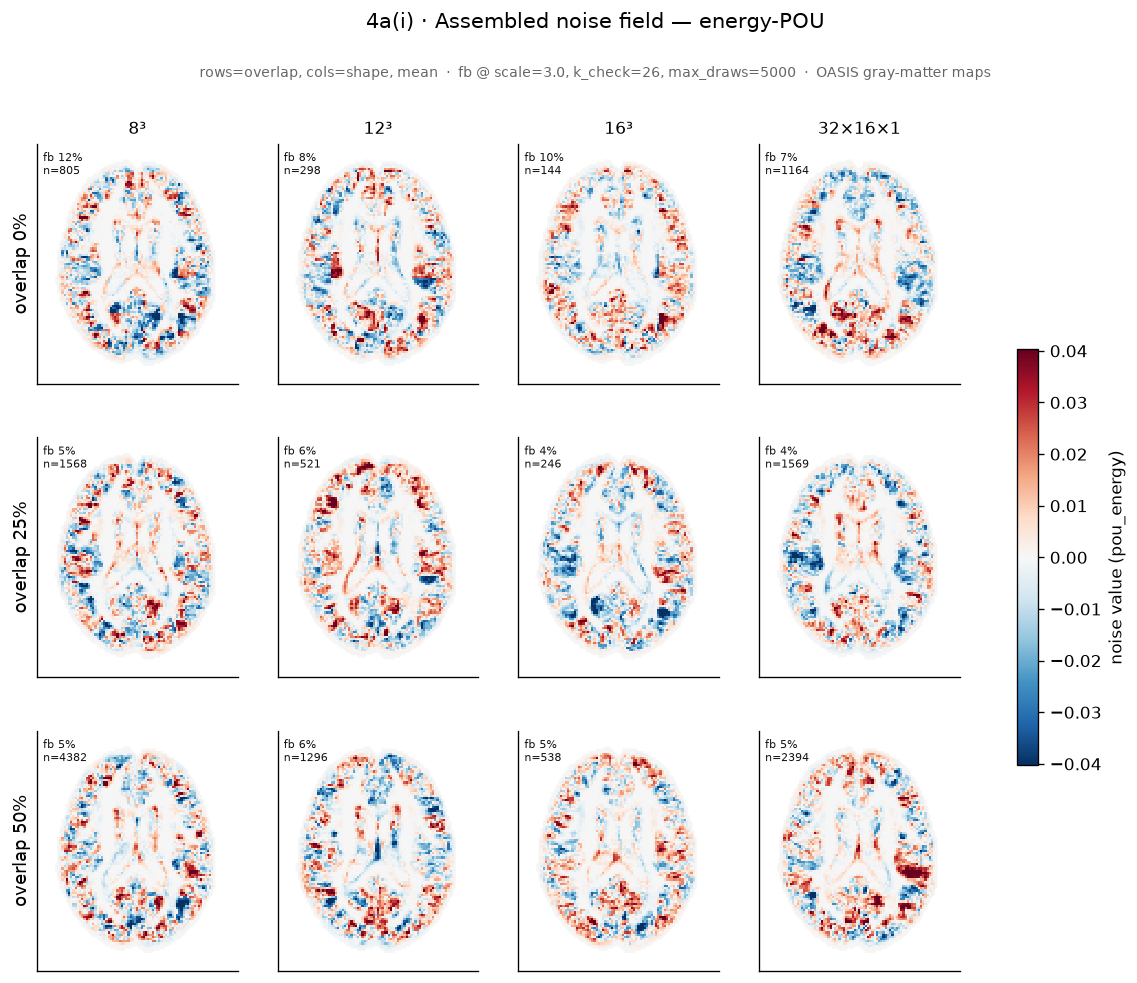

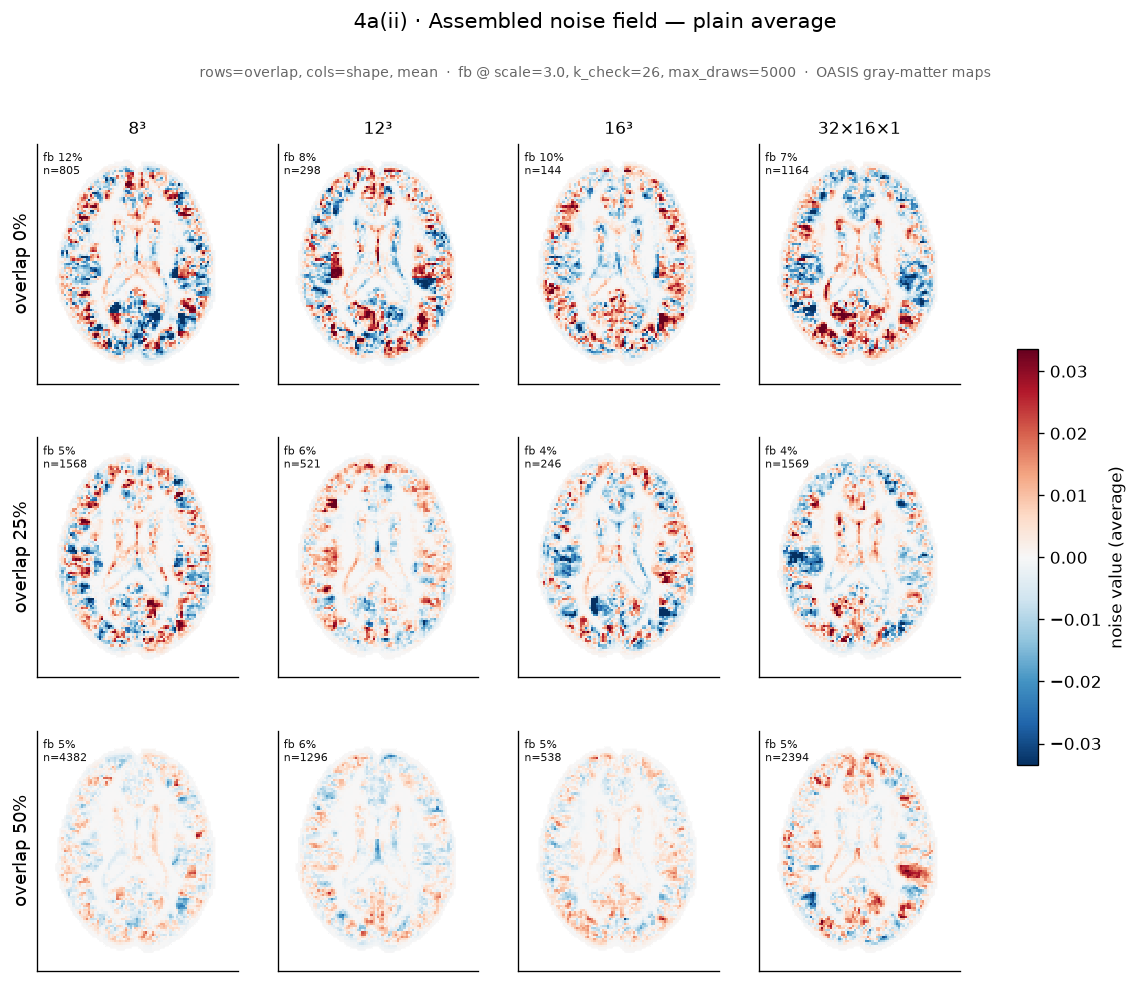

[fallback] fb in each cell = share of THAT cell's patch runs (n) that tail-filled; identical across the two blends (a per-patch property). It varies with patch size/overlap/statistic — see 4e.


In [18]:
# 4a -- assembled noise field, shown for TWO blends: energy-POU and plain average (rows=overlap,
# cols=shape). Fallback (fb) is a per-patch property, so it is identical for both blends.
grid_stat = "mean"
_labels = {"pou_energy": "4a(i) · Assembled noise field — energy-POU",
           "average":    "4a(ii) · Assembled noise field — plain average"}
for blend in ["pou_energy", "average"]:
    allf = [SW[(grid_stat, nm, o)]["fields"][blend][MASK] for nm in SHAPES for o in OVERLAPS]
    vmn, vmx = robust_sym(np.concatenate(allf))
    fig, axes = plt.subplots(len(OVERLAPS), len(SHAPES),
                             figsize=(3.1*len(SHAPES), 3.0*len(OVERLAPS)), squeeze=False)
    for i, o in enumerate(OVERLAPS):
        for j, nm in enumerate(SHAPES):
            im = show(axes[i, j], np.where(MASK, SW[(grid_stat, nm, o)]["fields"][blend], np.nan)[:, :, zc].T,
                      CMAP_DIV, vmin=vmn, vmax=vmx, outline=MASK_AX)
            _fr = SW[(grid_stat, nm, o)]["fallback_rate"]; _n = SW[(grid_stat, nm, o)]["n_patches"]
            if i == 0: axes[i, j].set_title(f"{DISP[nm]}", fontsize=10)
            axes[i, j].text(0.03, 0.97, f"fb {_fr:.0%}\nn={_n}", transform=axes[i, j].transAxes,
                            va="top", ha="left", fontsize=6.5, color="#111",
                            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.6))
            if j == 0: axes[i, j].set_ylabel(f"overlap {int(o*100)}%", fontsize=11)
    fig.colorbar(im, ax=axes, shrink=0.5, label=f"noise value ({blend})")
    dualtitle(fig, _labels[blend],
              f"rows=overlap, cols=shape, {grid_stat}  ·  fb @ scale={MECH_SCALE}, k_check={MECH_KCHECK}, "
              f"max_draws={MECH_MAXDRAWS}  ·  {SUBSTRATE}", y_main=1.0, y_sub=0.95)
    plt.show()
print(f"[fallback] fb in each cell = share of THAT cell's patch runs (n) that tail-filled; identical across the "
      f"two blends (a per-patch property). It varies with patch size/overlap/statistic — see 4e.")

**The release, in three panels per statistic.** Left is the clean statistic map; middle is the
assembled noise field that gets added; right is the **noisy release** (clean + noise) — what actually
leaves the pipeline. One row per statistic, for a representative configuration.

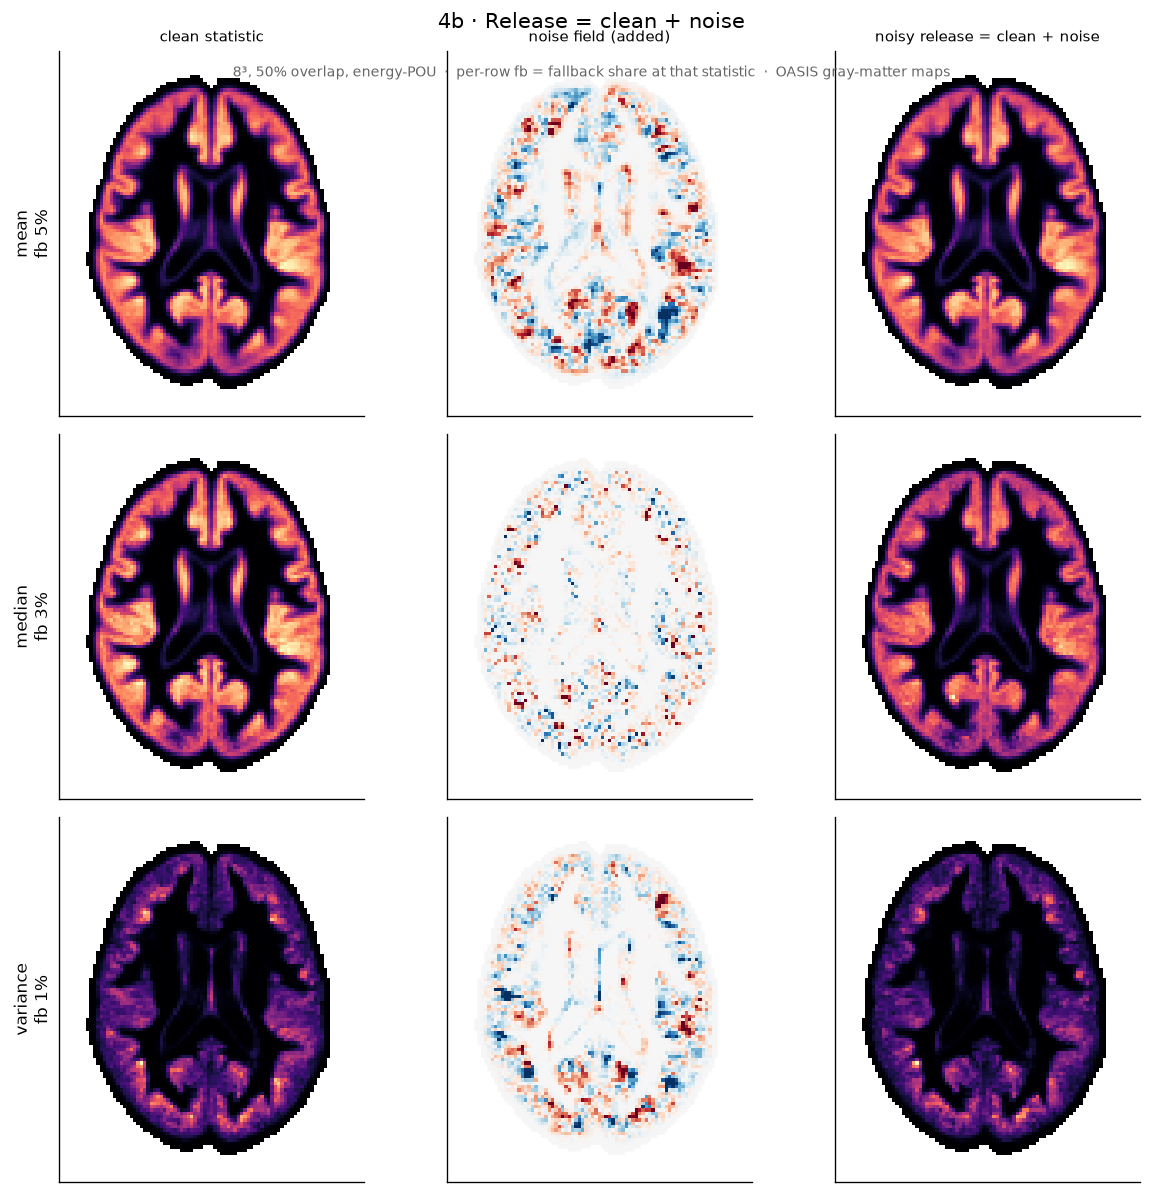

In [19]:
tri_shape, tri_ovl = "8x8x8", 0.5
fig, axes = plt.subplots(len(STATS), 3, figsize=(10.5, 3.3*len(STATS)))
for i, st in enumerate(STATS):
    R = SW[(st, tri_shape, tri_ovl)]; fld = R["fields"]["pou_energy"]; clean = R["clean"]
    vmn, vmx = robust_sym(fld[MASK])
    show(axes[i,0], np.where(MASK, clean, np.nan)[:,:,zc].T, CMAP_MAG, title="clean statistic" if i==0 else None)
    show(axes[i,1], np.where(MASK, fld, np.nan)[:,:,zc].T, CMAP_DIV, vmin=vmn, vmax=vmx,
         title="noise field (added)" if i==0 else None, outline=MASK_AX)
    show(axes[i,2], np.where(MASK, clean+fld, np.nan)[:,:,zc].T, CMAP_MAG, title="noisy release = clean + noise" if i==0 else None)
    axes[i,0].set_ylabel(f"{st}\nfb {R['fallback_rate']:.0%}", fontsize=10)
plt.tight_layout()
dualtitle(fig, "4b · Release = clean + noise",
          f"{DISP[tri_shape]}, 50% overlap, energy-POU  ·  per-row fb = fallback share at that statistic  ·  {SUBSTRATE}",
          y_main=1.0, y_sub=0.955)
plt.show()

### 4c · Utility metrics

The harness `utility_panel` offers four measures; we use the three that capture distinct failure
modes here (bias-norm, the fourth, checks rejection-sampling bias and is ≈0 for this mechanism, so it
is omitted from the plot):

- **rel-MSE** — magnitude of distortion (noise power / signal power); lower is better.
- **neighbour-corr gap** — |spatial neighbour-correlation(clean) − neighbour-correlation(released)|;
  the *imaging-specific* axis that MSE is blind to (iid noise inflates it). Lower is better.
- **Spearman** — rank/ordering preservation across voxels; 1 means the ordering is intact.

Rows are the three metrics, columns are the statistics, lines are the blends, x is overlap, with 95%
CI bands over seeds. Watch that plain average's *lower* rel-MSE at high overlap is noise shrinkage —
the same effect would reduce privacy — whereas energy-POU holds.

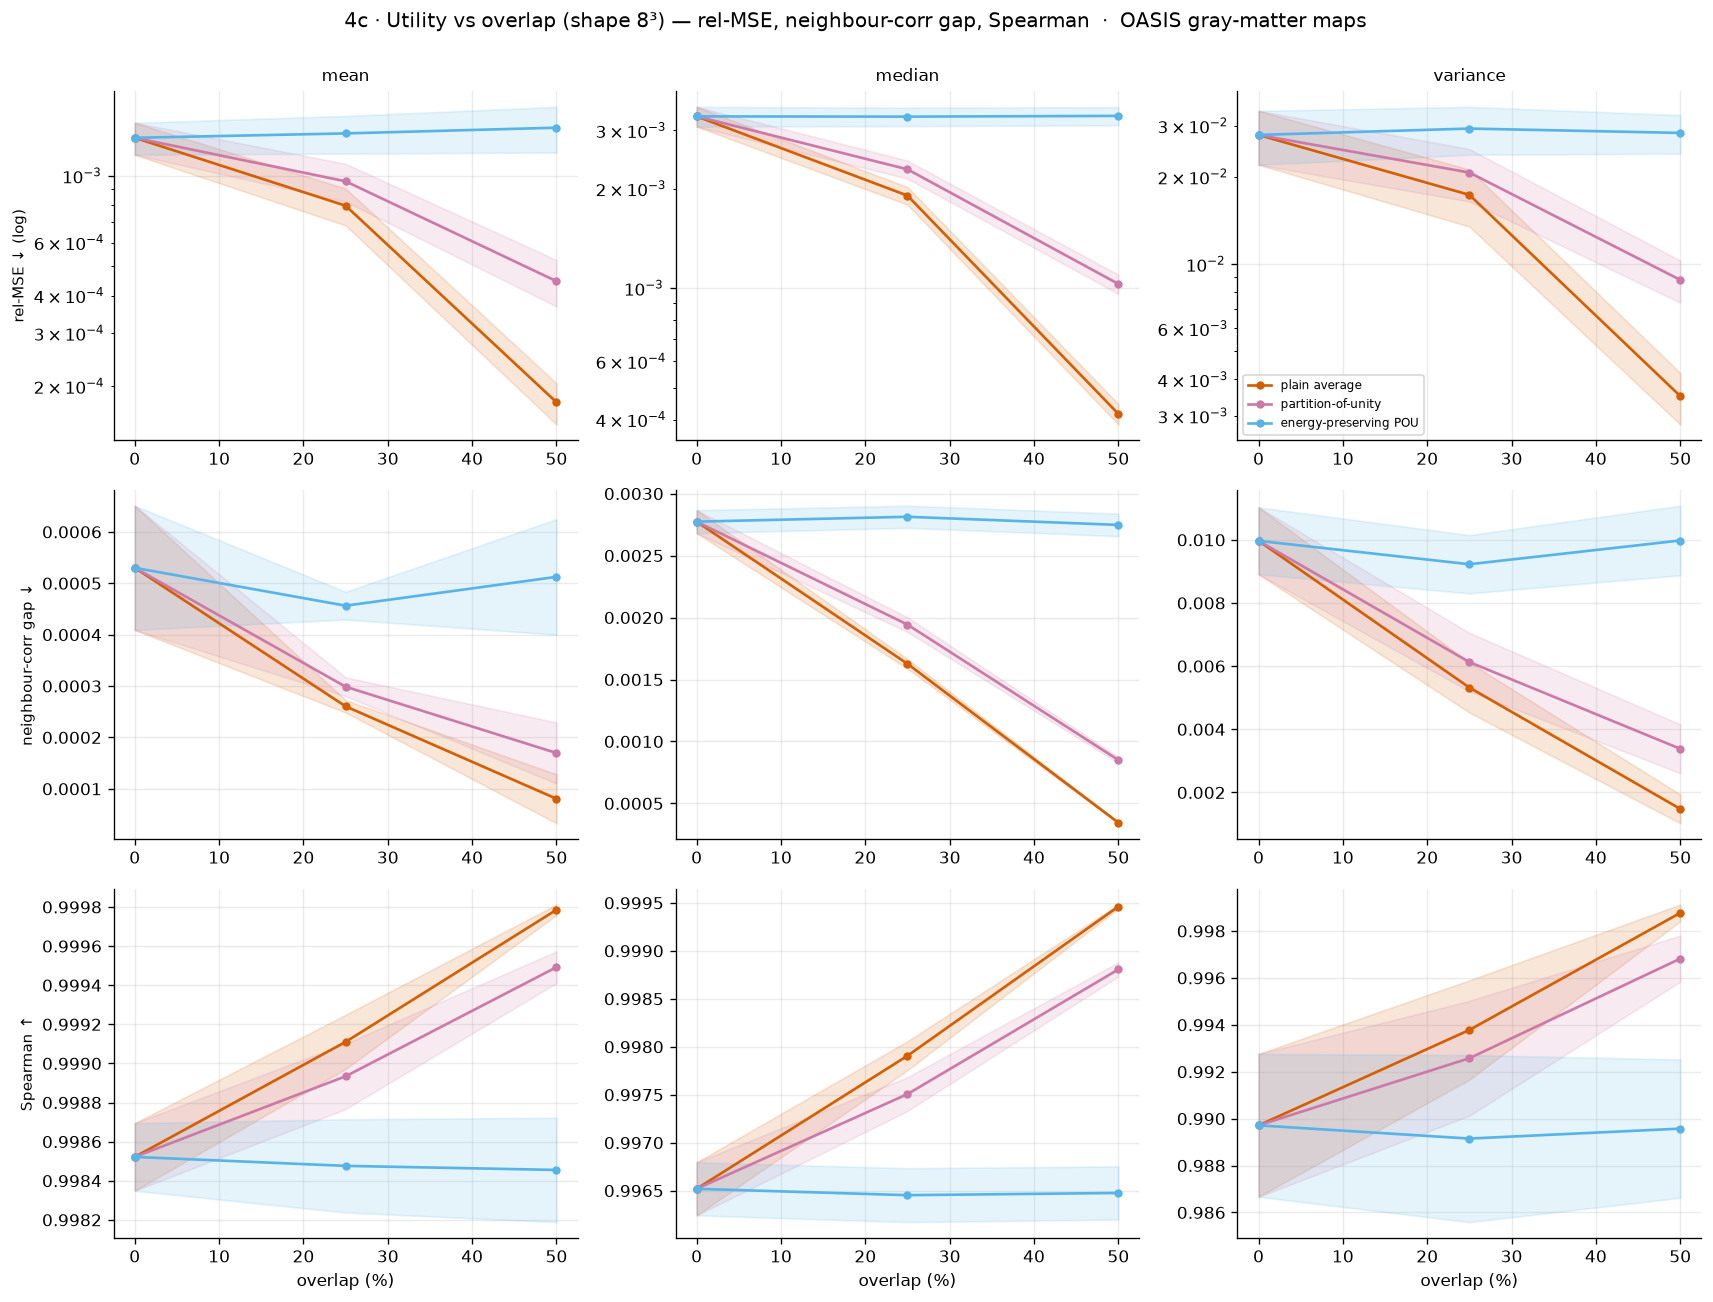

[note] plain-average (orange) and POU (pink) nearly coincide — they are weighted averages of the
       same per-patch draws; POU differs only at seams, energy-POU in magnitude.


In [20]:
curve_shape = "8x8x8"
metrics = [("rel_mse","rel-MSE ↓ (log)","log"),
           ("neighbour_corr_gap","neighbour-corr gap ↓","linear"),
           ("spearman","Spearman ↑","linear")]
fig, axes = plt.subplots(len(metrics), len(STATS), figsize=(4.8*len(STATS), 3.6*len(metrics)), squeeze=False)
for r,(metric,ylab,scale) in enumerate(metrics):
    for c, st in enumerate(STATS):
        a = axes[r,c]
        for b in BLENDS_REL:
            ys,los,his = [],[],[]
            for o in OVERLAPS:
                sub = UTIL[(UTIL.stat==st)&(UTIL.shp==curve_shape)&(UTIL.overlap==o)&(UTIL.blend==b)]
                m,lo,hi = ci95(sub[metric].values); ys.append(m); los.append(lo); his.append(hi)
            xx=[int(o*100) for o in OVERLAPS]
            a.plot(xx, ys, "o-", color=C_BLEND[b], lw=1.6, ms=4, label=BL_DISP[b])
            a.fill_between(xx, los, his, color=C_BLEND[b], alpha=0.15)
        a.set_yscale(scale)
        if r==0: a.set_title(st, fontsize=10)
        if r==len(metrics)-1: a.set_xlabel("overlap (%)")
        if c==0: a.set_ylabel(ylab, fontsize=9)
axes[0,-1].legend(fontsize=7)
fig.suptitle(f"4c · Utility vs overlap (shape {DISP[curve_shape]}) — rel-MSE, neighbour-corr gap, Spearman  ·  {SUBSTRATE}", y=1.0)
plt.tight_layout(); plt.show()
print("[note] plain-average (orange) and POU (pink) nearly coincide — they are weighted averages of the\n"
      "       same per-patch draws; POU differs only at seams, energy-POU in magnitude.")

### 4d · Utility across shape × overlap

Each heatmap summarizes one metric over the full shape×overlap plane for the energy-POU release, per
statistic. **How the single rel-MSE number is computed:** for each configuration it is
`mean over in-brain voxels of (noise²)` divided by `mean over in-brain voxels of (clean signal²)`,
averaged over seeds — a whole-brain **relative mean squared error** (total noise power / total signal
power). We use the *mean* over voxels, not a median: MSE is an energy quantity, so the sum of squared
errors is the meaningful total, and the mean is that total per voxel; a median would hide the
high-error rim and seam voxels, which are exactly the privacy-relevant tail. The colour map is
oriented so **low rel-MSE is dark and high is bright**. SSIM (structural similarity, higher=better)
is shown alongside.

rel_mse: 216 finite values across 2 blends.


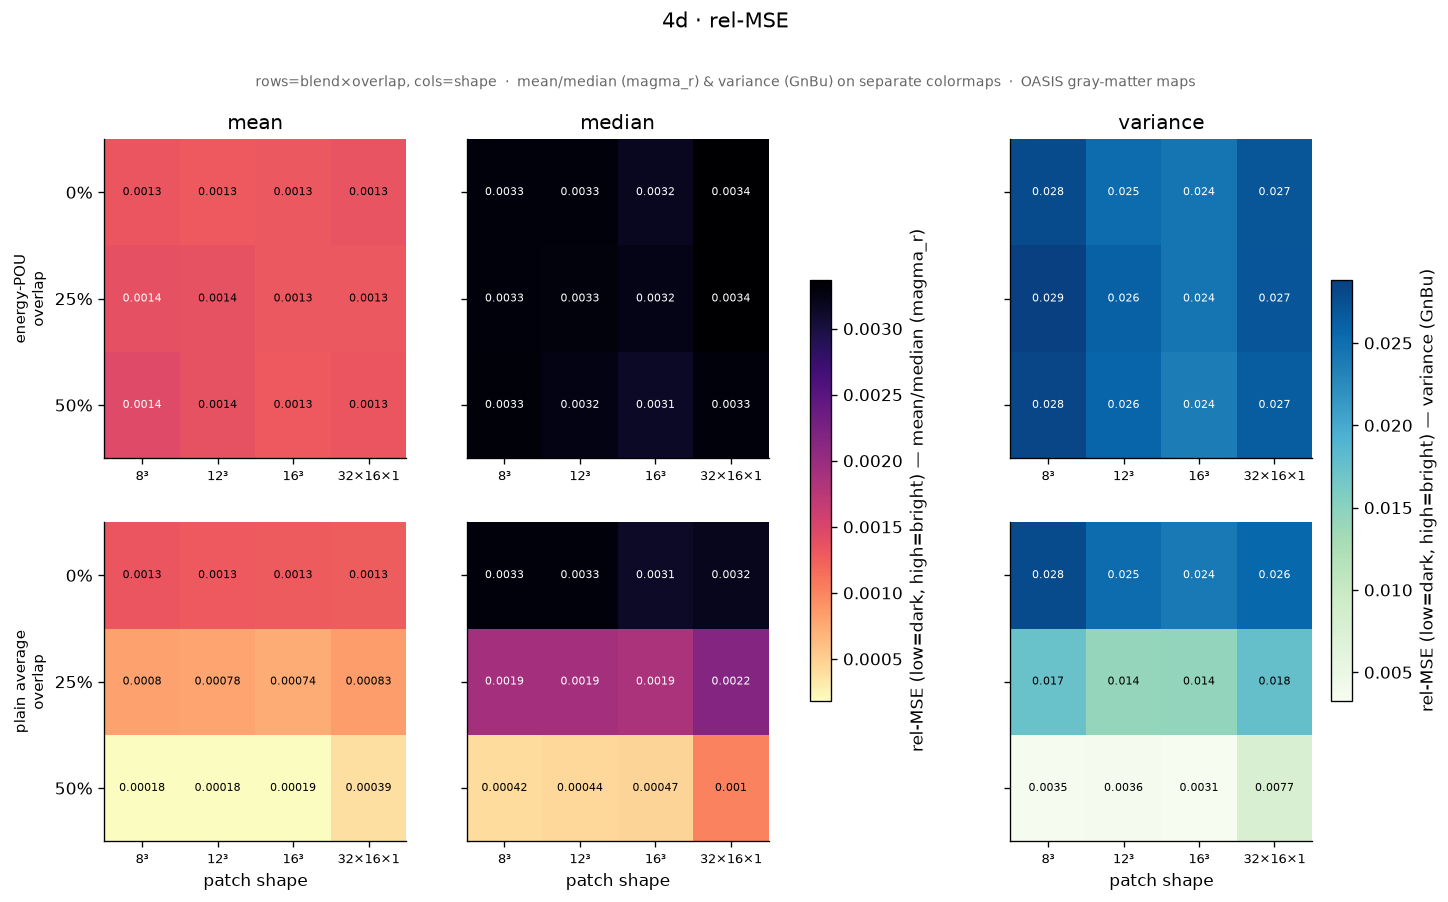


ssim: 0 finite values across 2 blends.
Skipping ssim: no finite values.


In [34]:
_blends_4d = [("pou_energy", "energy-POU"), ("average", "plain average")]
for metric, mlabel, cmap, cmap_var in [("rel_mse", "rel-MSE (low=dark, high=bright)", "magma_r", "GnBu"),
                                       ("ssim", "SSIM (higher=better)", "viridis", "OrRd")]:
    M = {bk: {} for bk, _ in _blends_4d}; finite = 0
    for bk, _ in _blends_4d:
        for st in STATS:
            g = np.full((len(OVERLAPS), len(SHAPES)), np.nan)
            for i, o in enumerate(OVERLAPS):
                for j, nm in enumerate(SHAPES):
                    sub = UTIL[(UTIL.stat == st) & (UTIL.shp == nm) & (UTIL.overlap == o) & (UTIL.blend == bk)]
                    v = sub[metric].to_numpy(float); v = v[np.isfinite(v)]; finite += v.size
                    if v.size: g[i, j] = v.mean()
            M[bk][st] = g
    print(f"{metric}: {finite} finite values across {len(_blends_4d)} blends.", flush=True)
    # two independent colour scales: {mean,median} share one, variance gets its own (it is ~20x larger)
    def _lim(stats_in):
        a = np.concatenate([M[bk][st].ravel() for bk, _ in _blends_4d for st in stats_in if st in STATS])
        a = a[np.isfinite(a)]
        if a.size == 0: return None
        lo, hi = np.percentile(a, [2, 98])
        if lo == hi: p = max(abs(lo)*0.01, 1e-9); lo, hi = lo-p, hi+p
        return (lo, hi)
    limA = _lim([s for s in ["mean", "median"] if s in STATS]); limB = _lim(["variance"]) if "variance" in STATS else None
    if limA is None and limB is None:
        print(f"Skipping {metric}: no finite values."); continue
    cm = plt.get_cmap(cmap).copy(); cm.set_bad("lightgray")
    cmv = plt.get_cmap(cmap_var).copy(); cmv.set_bad("lightgray")
    fig, axes = plt.subplots(len(_blends_4d), len(STATS), figsize=(4.6*len(STATS), 3.8*len(_blends_4d)), squeeze=False)
    imA = imB = None
    for r, (bk, blab) in enumerate(_blends_4d):
        for ci, st in enumerate(STATS):
            a = axes[r, ci]; g = M[bk][st]
            lim = limB if st == "variance" else limA
            vmn, vmx = lim if lim else (0, 1)
            _cm = cmv if st == "variance" else cm
            im = a.imshow(np.ma.masked_invalid(g), cmap=_cm, vmin=vmn, vmax=vmx, aspect="auto"); a.grid(False)
            if st == "variance": imB = im
            else: imA = im
            a.set_xticks(range(len(SHAPES))); a.set_xticklabels([DISP[nm] for nm in SHAPES], fontsize=8)
            a.set_yticks(range(len(OVERLAPS))); a.set_yticklabels([f"{int(o*100)}%" for o in OVERLAPS] if ci == 0 else [])
            if r == 0: a.set_title(st)
            if ci == 0: a.set_ylabel(f"{blab}\noverlap", fontsize=9)
            if r == len(_blends_4d)-1: a.set_xlabel("patch shape")
            for i in range(len(OVERLAPS)):
                for j in range(len(SHAPES)):
                    v = g[i, j]
                    if not np.isfinite(v): a.text(j, i, "n/a", ha="center", va="center", fontsize=7); continue
                    fr = np.clip((v-vmn)/(vmx-vmn), 0, 1); rr, gg, bb, _ = (cmv if st=="variance" else cm)(fr)
                    a.text(j, i, f"{v:.2g}", ha="center", va="center", fontsize=6.5,
                           color="w" if 0.299*rr+0.587*gg+0.114*bb < 0.5 else "k")
    axA = [axes[r, ci] for r in range(len(_blends_4d)) for ci, st in enumerate(STATS) if st != "variance"]
    axB = [axes[r, ci] for r in range(len(_blends_4d)) for ci, st in enumerate(STATS) if st == "variance"]
    if imA is not None and axA: fig.colorbar(imA, ax=axA, shrink=0.6, label=f"{mlabel} — mean/median ({cmap})")
    if imB is not None and axB: fig.colorbar(imB, ax=axB, shrink=0.6, label=f"{mlabel} — variance ({cmap_var})")
    dualtitle(fig, f"4d · {mlabel.split(' (')[0]}",
              f"rows=blend×overlap, cols=shape  ·  mean/median ({cmap}) & variance ({cmap_var}) on separate colormaps  ·  {SUBSTRATE}",
              y_main=1.02, y_sub=0.95)
    plt.show(); print()

### 4e · Fallback behaviour across the full tiling

A patch *falls back* when its rejection sampler exhausts `max_draws` and tail-fills the modes that never cleared their bar simultaneously; it is counted **once per patch release** (denominator = patch runs). This is the same regime as 6.5 (k_check=39 polices all r modes, so the joint per-draw acceptance is small). Here we show how it breaks down across the whole tiling at the configured operating point — by overlap×shape, by in-brain fraction (interior vs boundary-fill), and by statistic.

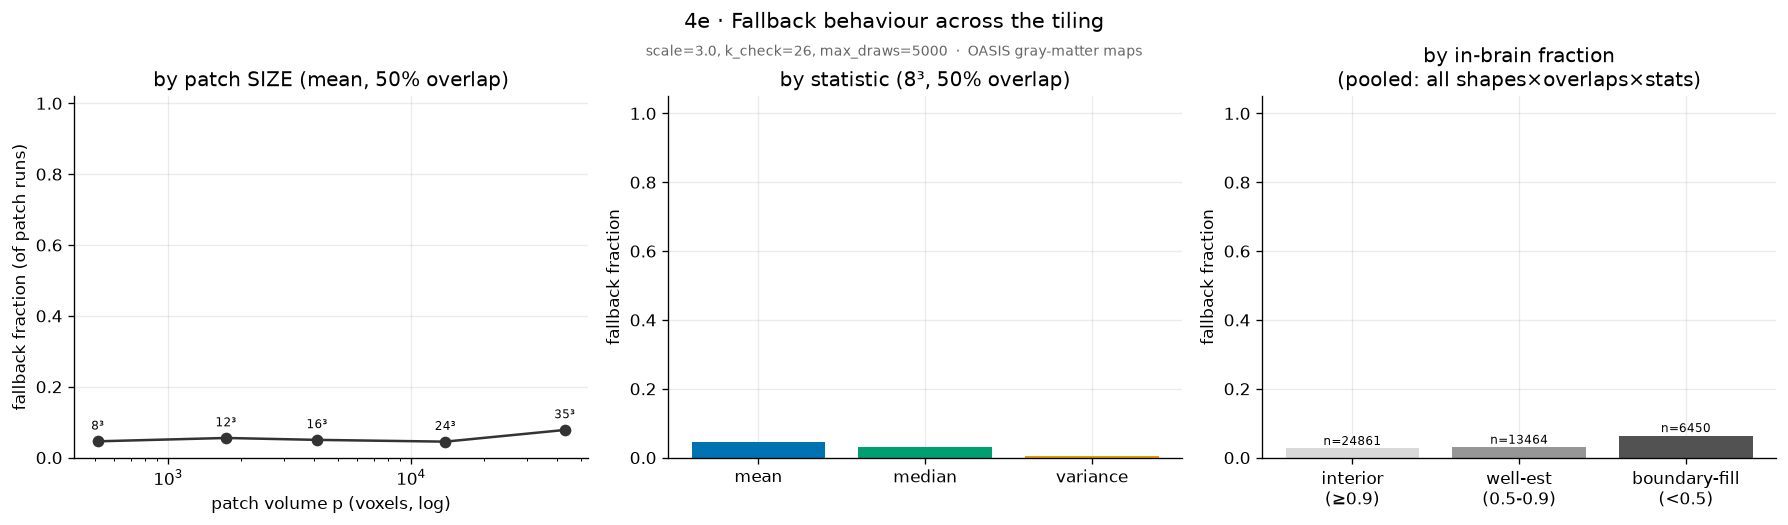

[read-off] Panel 1 is the key result: fallback falls steeply with patch VOLUME (8³ ≈ 5% down to 35³ ≈ 8%) — reproducing 6.5's §3a size effect on the real tiling. 7.1 uses small patches, so it sits at the high-fallback end. By statistic, median is hardest, variance easiest. Panel 3 pools boundary-fill patches over ALL shapes & overlaps — they arise almost entirely at 0%/25% overlap (at 50% there are few), so that bar is not tied to one size/overlap. A fallback patch still satisfies all bars (unmet modes tail-filled).


In [22]:
# 4e -- fallback across the tiling. Panel 1 is the key size effect: small patches fall back far more
# than big ones (matches 6.5 's 3a map: 8^3 ~0.65, 35^3 ~0.27 at this operating point). Colours encode
# each panel's OWN axis only (no shared meaning across panels).
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
# (1) fallback vs patch VOLUME (mean, representative overlap). Reuse the sweep for sizes in SHAPES;
#     compute a few larger CUBES fresh so the small->big decline is visible on one axis.
_vol_ovl = OVERLAPS[-1]
vol_pts = []
for s in [8, 12, 16, 24, 35]:
    ps = (s, s, s)
    if not all(d <= D for d, D in zip(ps, VOLSHAPE)): continue
    nm = f"{s}x{s}x{s}"
    fr = (SW[("mean", nm, _vol_ovl)]["fallback_rate"] if nm in SHAPES
          else A_FIELD(COHORT[0], MASK, "mean", ps, _vol_ovl, base_seed=0, min_frac=MIN_FRAC)["fallback_rate"])
    vol_pts.append((s**3, fr, f"{s}³"))
vol_pts.sort()
axes[0].plot([p for p, _, _ in vol_pts], [f for _, f, _ in vol_pts], "o-", color="#333333", ms=6)
for p, f, l in vol_pts:
    axes[0].annotate(l, (p, f), fontsize=7, xytext=(0, 7), textcoords="offset points", ha="center")
axes[0].set_xscale("log")
axes[0].set(xlabel="patch volume p (voxels, log)", ylabel="fallback fraction (of patch runs)",
            title=f"by patch SIZE (mean, {int(_vol_ovl*100)}% overlap)", ylim=(0, 1.02))
# (2) by statistic at a representative size/overlap -- colours = the canonical per-statistic palette
_rs = "8x8x8" if "8x8x8" in SHAPES else list(SHAPES)[0]; _ro = OVERLAPS[-1]
axes[1].bar(STATS, [SW[(st, _rs, _ro)]["fallback_rate"] for st in STATS], color=[C_STAT[s] for s in STATS])
axes[1].set(ylabel="fallback fraction", title=f"by statistic ({DISP[_rs]}, {int(_ro*100)}% overlap)", ylim=(0, 1.05))
# (3) by in-brain fraction, pooled -- a neutral grey ramp (interior->boundary), no clash with the above
allfb = np.concatenate([SW[(st, nm, o)]["fallbacks"] for st in STATS for nm in SHAPES for o in OVERLAPS])
allfr = np.concatenate([SW[(st, nm, o)]["patch_frac"] for st in STATS for nm in SHAPES for o in OVERLAPS])
bins = [("interior\n(≥0.9)", allfr >= 0.9), ("well-est\n(0.5-0.9)", (allfr >= 0.5) & (allfr < 0.9)),
        ("boundary-fill\n(<0.5)", allfr < 0.5)]
vals = [allfb[sel].mean() if sel.any() else 0.0 for _, sel in bins]; ns = [int(sel.sum()) for _, sel in bins]
bars = axes[2].bar([b[0] for b in bins], vals, color=["#d9d9d9", "#969696", "#525252"])
for bar, n in zip(bars, ns):
    axes[2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f"n={n}", ha="center", fontsize=7)
axes[2].set(ylabel="fallback fraction", title="by in-brain fraction\n(pooled: all shapes×overlaps×stats)", ylim=(0, 1.05))
plt.tight_layout()
dualtitle(fig, "4e · Fallback behaviour across the tiling",
          f"scale={MECH_SCALE}, k_check={MECH_KCHECK}, max_draws={MECH_MAXDRAWS}  ·  {SUBSTRATE}", y_main=1.03, y_sub=0.965)
plt.show()
print(f"[read-off] Panel 1 is the key result: fallback falls steeply with patch VOLUME ({vol_pts[0][2]} "
      f"≈ {vol_pts[0][1]:.0%} down to {vol_pts[-1][2]} ≈ {vol_pts[-1][1]:.0%}) — reproducing 6.5's §3a size "
      f"effect on the real tiling. 7.1 uses small patches, so it sits at the high-fallback end. By statistic, "
      f"median is hardest, variance easiest. Panel 3 pools boundary-fill patches over ALL shapes & overlaps — "
      f"they arise almost entirely at 0%/25% overlap (at 50% there are few), so that bar is not tied to one size/overlap. "
      f"A fallback patch still satisfies all bars (unmet modes tail-filled).")

## 5 · Patch-rank distribution

Each patch's noise covariance has a structural rank — read from the **raw** Cov(LOO) perturbations
(the mechanism floors its sampling covariance to full rank, so that regularized object would hide
this). Two different numbers live here, and it matters which one is quoted for privacy:

- **Full (numerical) rank** — the count of non-zero LOO modes, capped at min(p, N−1)=min(p, 39). This
  is the **privacy-relevant** rank: notebook 6.1 showed leakage lives in *all* of these modes,
  including the low-variance tail, so the noise must cover the full rank — it **cannot** be truncated.
- **95%-energy effective rank** — how many modes hold 95% of the noise *energy* (small here). This is
  a **structural descriptor** of where the noise concentrates, **not** a privacy budget. A low
  effective rank does *not* license truncation (the fallacy 6.1 refuted).

Rank is a property of each patch, independent of overlap; overlap only changes how many patches there
are and where they sit.

**What the annotation `well-estimated (total)` means.** Every patch tiled at a setting is a *total*
patch, and that includes the boundary coverage-fill patches added (§4) so no voxel goes unprotected.
Those boundary patches contain only a few in-brain voxels, so their covariance — and hence their rank
— is artificially low and would drag the distribution down. A patch is **well-estimated** when its
in-brain fraction ≥ `min_frac` (0.5): enough in-brain voxels for a trustworthy covariance. The violin
is drawn from the well-estimated patches only; the annotation reads `<#well-estimated> (<#total>)`, so
`183 (226)` means 183 well-estimated patches shown out of 226 patches tiled in all.

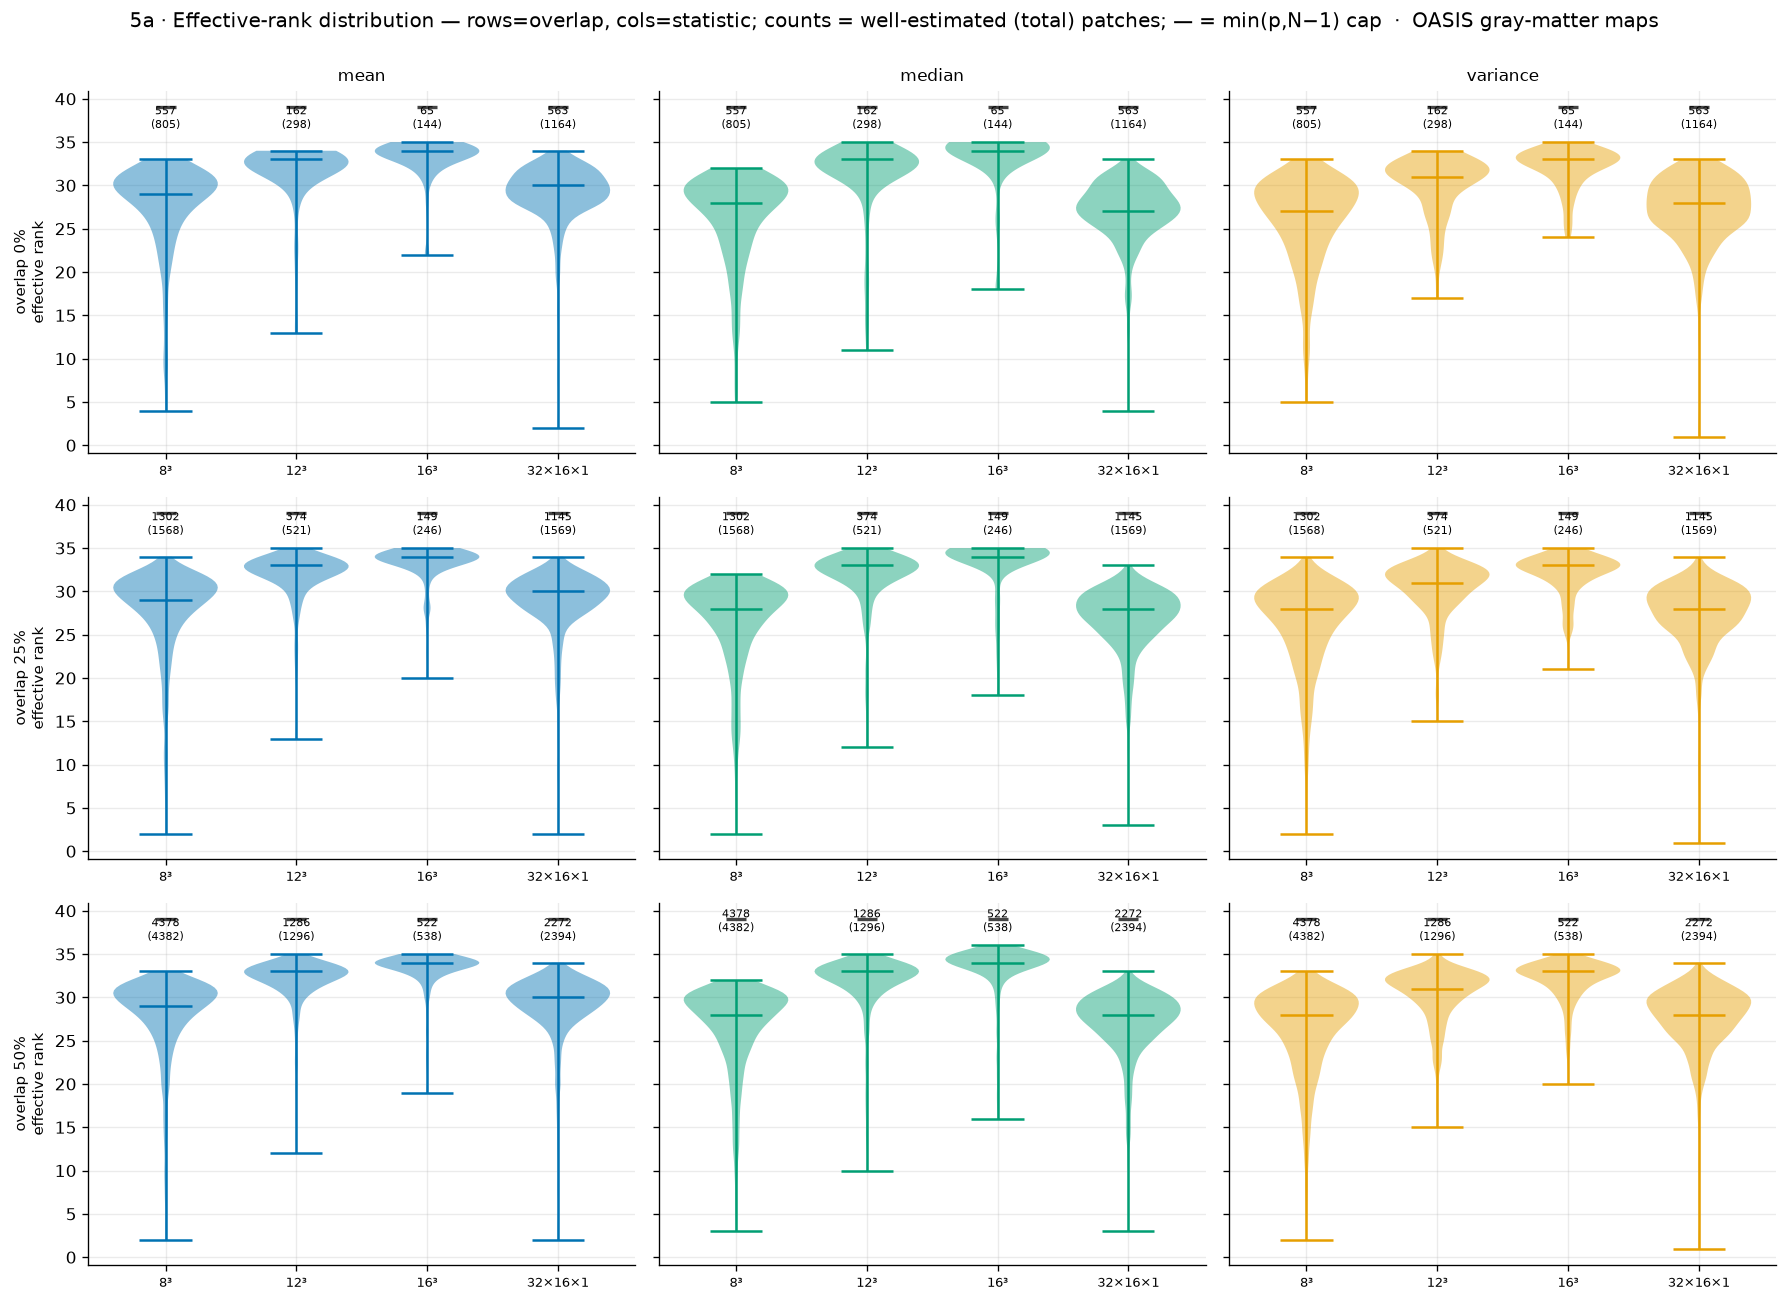

In [23]:
# Figure 5a — effective-rank violins: rows = overlap, cols = statistic, one violin per shape, counts annotated
fig, axes = plt.subplots(len(OVERLAPS), len(STATS), figsize=(5*len(STATS), 3.6*len(OVERLAPS)), squeeze=False, sharey=True)
for r, o in enumerate(OVERLAPS):
    for c, st in enumerate(STATS):
        a = axes[r,c]
        data, counts = [], []
        for nm in SHAPES:
            R = SW[(st,nm,o)]; q = R["patch_frac"] >= MIN_FRAC
            data.append(R["eff"][q] if q.any() else np.array([0]))
            counts.append((int(q.sum()), int(len(R["eff"]))))
        parts = a.violinplot(data, showmedians=True, widths=0.8)
        for pc in parts["bodies"]: pc.set_facecolor(C_STAT[st]); pc.set_alpha(0.45)
        for key in ("cmedians","cbars","cmins","cmaxes"):
            if key in parts: parts[key].set_color(C_STAT[st])
        for i, nm in enumerate(SHAPES):
            cap = min(int(np.prod(SHAPES[nm])), N-1); a.plot(i+1, cap, "_", color="#444", ms=12, mew=2)
            top = max([d.max() for d in data if len(d)]+[1])
            a.text(i+1, top*1.02+0.5, f"{counts[i][0]}\n({counts[i][1]})", ha="center", va="bottom", fontsize=6.5)
        a.set_xticks(range(1,len(SHAPES)+1)); a.set_xticklabels([DISP[n] for n in SHAPES], fontsize=8)
        if r==0: a.set_title(st, fontsize=10)
        if c==0: a.set_ylabel(f"overlap {int(o*100)}%\neffective rank", fontsize=9)
fig.suptitle(f"5a · Effective-rank distribution — rows=overlap, cols=statistic; counts = well-estimated (total) patches; "
             f"— = min(p,N−1) cap  ·  {SUBSTRATE}", y=1.0)
plt.tight_layout(); plt.show()

**Shape at matched volume.** The three ~64-voxel shapes (4³, flat 8×8×1, column 2×2×16) isolate
the effect of patch *shape* at fixed voxel count, for the mean at 50% overlap.

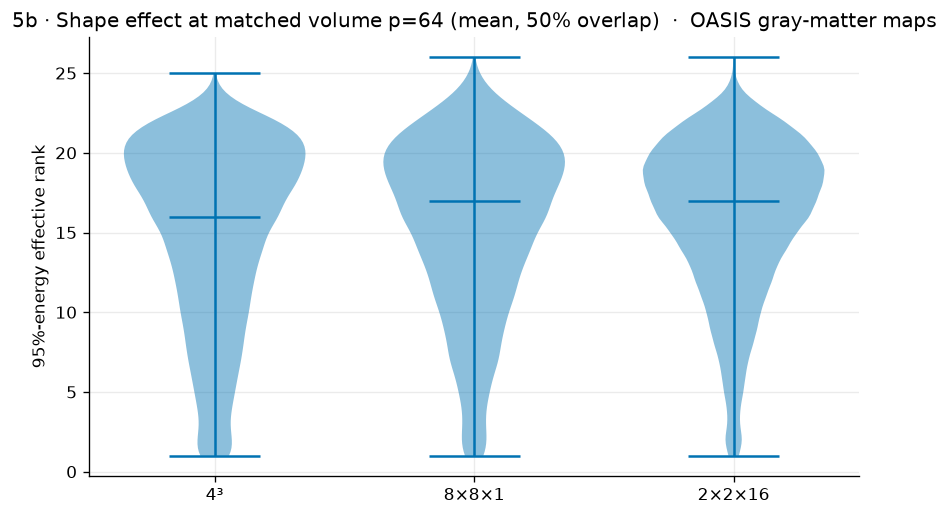

In [24]:
# 5b -- shape effect at FIXED volume (p=64). The matched family is NOT in the main sweep, so compute
# it on demand here; this makes 5b robust to any change in SHAPES (previously it went blank).
matched = list(MATCHED_SHAPES)
_mdata, _mok = [], []
for nm in matched:
    try:
        Rm = A_FIELD(COHORT[0], MASK, "mean", MATCHED_SHAPES[nm], 0.5, base_seed=0, min_frac=MIN_FRAC)
        q = Rm["patch_frac"] >= MIN_FRAC
        ev = Rm["eff"][q] if q.any() else Rm["eff"]
        _mdata.append(ev if len(ev) else np.array([0])); _mok.append(nm)
    except Exception as e:
        print(f"  [skip {nm}] {type(e).__name__}: {e}")
fig, ax = plt.subplots(figsize=(7.2, 4.4))
if _mdata:
    parts = ax.violinplot(_mdata, showmedians=True, widths=0.7)
    for pc in parts["bodies"]: pc.set_facecolor("#0072B2"); pc.set_alpha(0.45)
    for key in ("cmedians","cbars","cmins","cmaxes"):
        if key in parts: parts[key].set_color("#0072B2")
    ax.set_xticks(range(1, len(_mok)+1)); ax.set_xticklabels([MATCHED_DISP[n] for n in _mok])
    ax.set_ylabel("95%-energy effective rank")
else:
    ax.text(0.5, 0.5, "no matched-volume shapes available", ha="center", va="center", transform=ax.transAxes)
ax.set_title(f"5b · Shape effect at matched volume p=64 (mean, 50% overlap)  ·  {SUBSTRATE}")
plt.tight_layout(); plt.show()

**Effective rank across the brain.** Each patch is drawn at its centre, coloured by its effective
rank. Rank is per-patch and overlap-independent, so we hold overlap at 50% and vary the two things
that actually move it: **patch size** (columns 4³, 6³, 8³) and **statistic** (rows mean, variance —
the two extremes; median sits between). One axial slice each. Look for spatial structure: smoother
regions concentrate energy in fewer modes (lower rank) than textured regions.

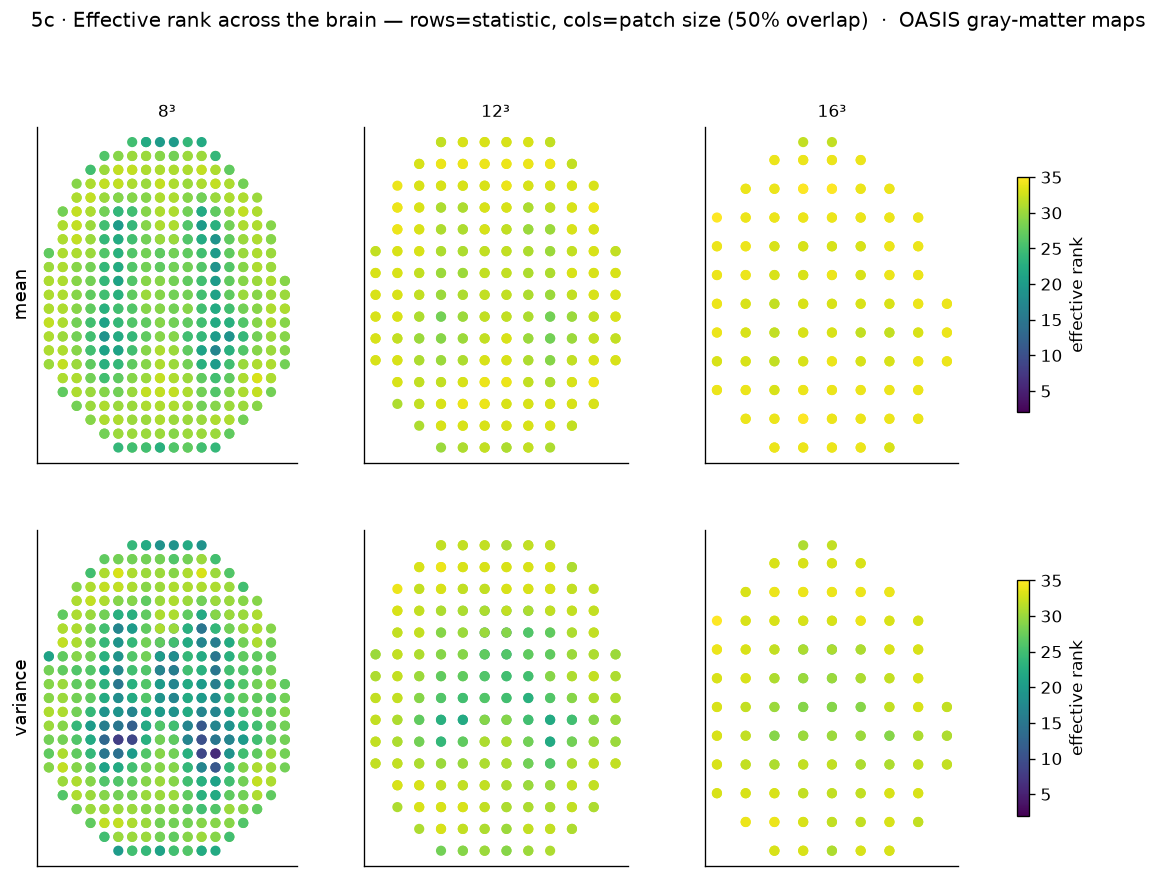

In [25]:
sel_stats = ["mean","variance"]
# derive the shown shapes from SHAPES (cubic sizes present, up to 3) -- was a hardcoded list
# that silently collapsed to one column when SHAPES changed (item 1 breakage fix)
_cubic = [n for n in SHAPES if len(set(SHAPES[n])) == 1]
sel_shapes = (_cubic[:3] if _cubic else list(SHAPES)[:3])
fig, axes = plt.subplots(len(sel_stats), len(sel_shapes), figsize=(4.2*len(sel_shapes), 4.0*len(sel_stats)), squeeze=False)
for r, st in enumerate(sel_stats):
    evs = np.concatenate([SW[(st,nm,0.5)]["eff"][SW[(st,nm,0.5)]["patch_frac"]>=MIN_FRAC] for nm in sel_shapes])
    vmn, vmx = (evs.min(), evs.max()) if evs.size else (0,1)
    for c, nm in enumerate(sel_shapes):
        R = SW[(st,nm,0.5)]; q = R["patch_frac"]>=MIN_FRAC; cen=R["centers"][q]; ev=R["eff"][q]
        selz = np.abs(cen[:,2]-zc) <= max(SHAPES[nm])/2
        sc = axes[r,c].scatter(cen[selz,0], cen[selz,1], c=ev[selz], cmap=CMAP_RANK, s=26, vmin=vmn, vmax=vmx)
        axes[r,c].set_aspect("equal"); axes[r,c].grid(False); axes[r,c].set_xticks([]); axes[r,c].set_yticks([])
        if r==0: axes[r,c].set_title(DISP[nm], fontsize=10)
        if c==0: axes[r,c].set_ylabel(st, fontsize=11)
    plt.colorbar(sc, ax=axes[r,:], shrink=0.7, label="effective rank")
fig.suptitle(f"5c · Effective rank across the brain — rows=statistic, cols=patch size (50% overlap)  ·  {SUBSTRATE}", y=1.0)
plt.show()

### 5d · Mask control — does the mask drive the rank shift?

Earlier notebooks saw effective rank ~5; here it sits ~30. The hypothesis under test: the new GM-threshold mask (vs the old union-of-nonzero mask) causes the shift. This cell holds **cohort, geometry, and statistic fixed** and varies **only the mask**. If `eff95` collapses toward ~5 under the union mask, the mask explains it; if it stays high, the **substrate** (real anatomical variability) does. Numerical rank is pinned at `min(p, N−1)=39` and is uninformative, so `eff95` (95%-energy) is the quantity compared — the *same* definition across notebooks.

                  mask  in_brain_vox  n_patch  eff95_median eff95_IQR
 GM-threshold (in use)        283966      557          29.0   [26,31]
union-of-nonzero (old)        871222     2016           2.0    [1,23]


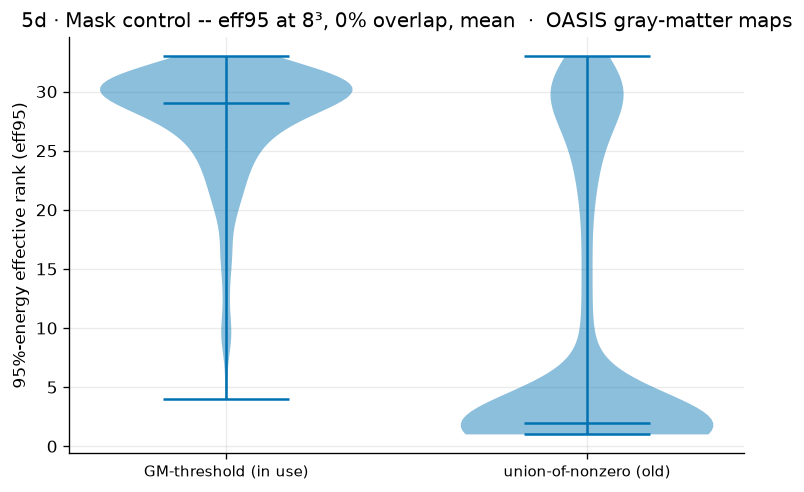

[read-off] a SMALL gap (union stays high) => mask is NOT the main driver; substrate dimensionality is.
           a LARGE drop (union -> ~5) would support the mask hypothesis. (Mimic predicts the former.)


In [26]:
# 5d -- controlled mask comparison (OASIS only; needs the two real masks). Cheap: one shape, 0% overlap.
if USE_OASIS:
    union_mask = np.abs(COHORT[0]).max(0) > 1e-6   # old union-of-nonzero support (~whole volume)
    _cmp_ps = SHAPES.get("8x8x8", (8, 8, 8))
    _rows, _evs = [], {}
    for lbl, mk in [("GM-threshold (in use)", MASK), ("union-of-nonzero (old)", union_mask)]:
        R = A_FIELD(COHORT[0], mk, "mean", _cmp_ps, 0.0, base_seed=0, min_frac=MIN_FRAC)
        q = R["patch_frac"] >= MIN_FRAC; ev = R["eff"][q]; _evs[lbl] = ev
        _rows.append({"mask": lbl, "in_brain_vox": int(mk.sum()), "n_patch": int(q.sum()),
                      "eff95_median": float(np.median(ev)),
                      "eff95_IQR": f"[{np.percentile(ev,25):.0f},{np.percentile(ev,75):.0f}]"})
    print(pd.DataFrame(_rows).to_string(index=False))
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    parts = ax.violinplot(list(_evs.values()), showmedians=True, widths=0.7)
    for pc in parts["bodies"]: pc.set_facecolor("#0072B2"); pc.set_alpha(0.45)
    for key in ("cmedians","cbars","cmins","cmaxes"):
        if key in parts: parts[key].set_color("#0072B2")
    ax.set_xticks([1, 2]); ax.set_xticklabels(list(_evs), fontsize=9)
    ax.set_ylabel("95%-energy effective rank (eff95)")
    ax.set_title(f"5d · Mask control -- eff95 at {DISP.get('8x8x8','8³')}, 0% overlap, mean  ·  {SUBSTRATE}")
    plt.tight_layout(); plt.show()
    print("[read-off] a SMALL gap (union stays high) => mask is NOT the main driver; substrate dimensionality is.\n"
          "           a LARGE drop (union -> ~5) would support the mask hypothesis. (Mimic predicts the former.)")
else:
    print("5d mask control: OASIS-only (needs the two real masks); skipped on the phantom profile.")

## 6 · Custom patch sizes

The full §4 + §5 treatment on your own sizes from the 6.3 autocorrelation study (edit `CUSTOM_SIZES`
in §0). The committed run keeps the custom overlap set light (`CUSTOM_OVERLAPS`); widen it in your
environment. The noise-field comparison is shown for mean, median **and** variance.

**Custom-patch tiling, three planes.** Before the noise/utility/rank analysis, here is how each custom size from §0 tiles the brain — GM anatomy beneath, mask outline, real mask-restricted patches (orange = well-estimated, pink = boundary-fill), on axial, coronal and sagittal slices.

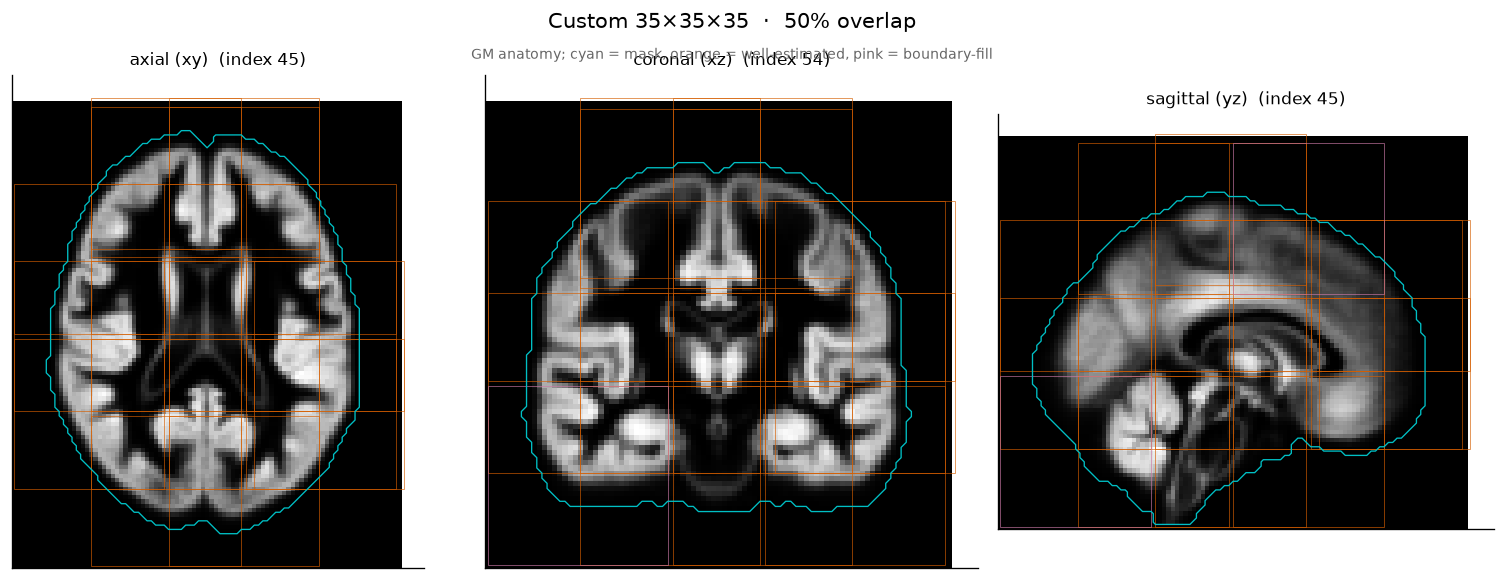

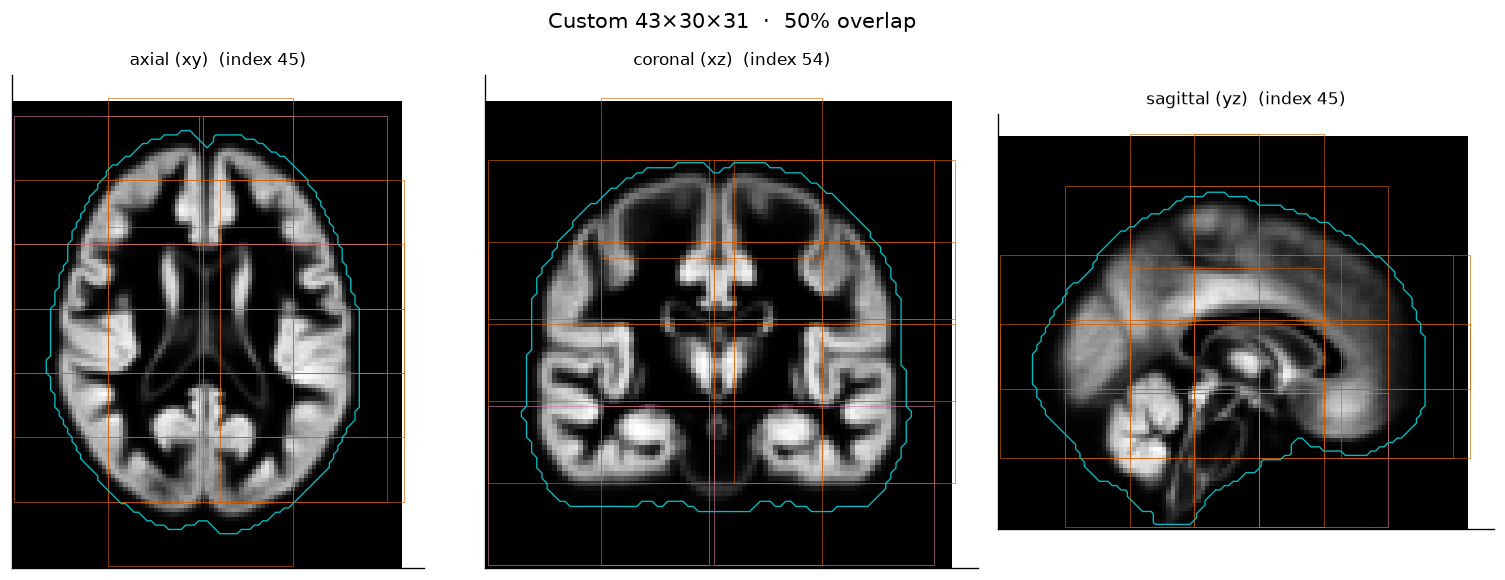

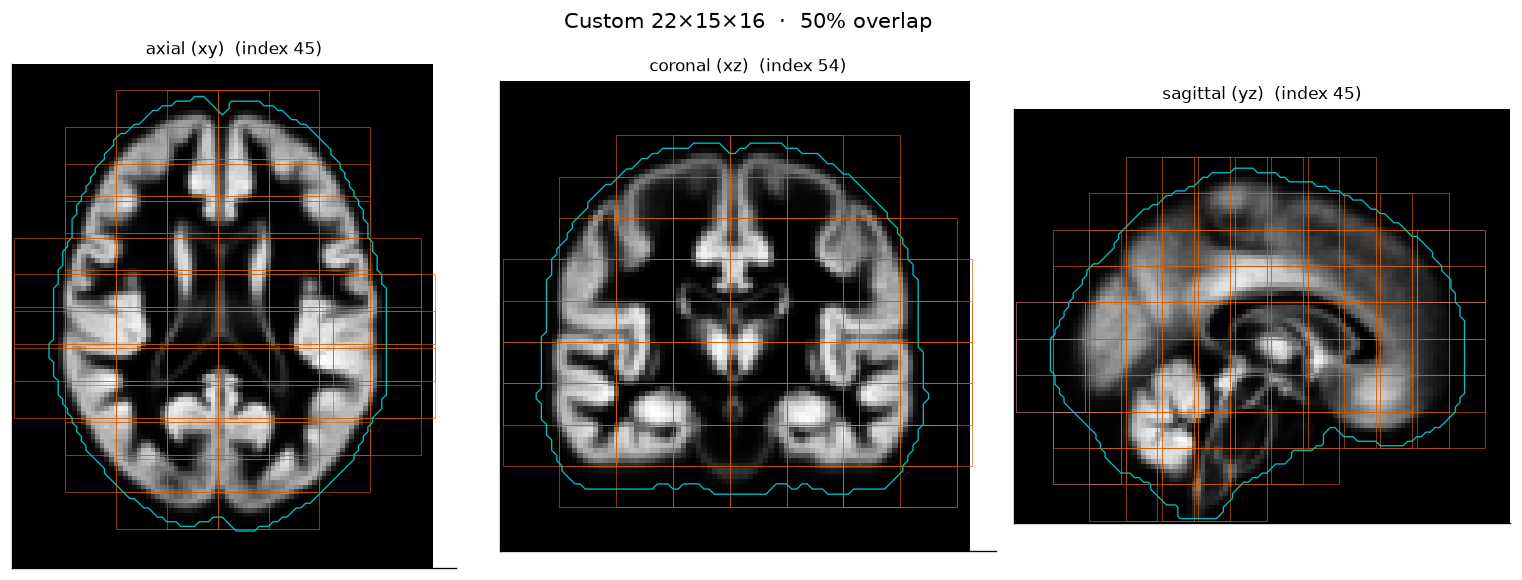

In [27]:
# §6 opens with the custom-size tiling on three planes (item 7)
CS = {k: v for k, v in CUSTOM_SIZES.items() if all(s <= d for s, d in zip(v, VOLSHAPE))}
if CS:
    _c_ovl = 0.5 if 0.5 in CUSTOM_OVERLAPS else CUSTOM_OVERLAPS[-1]
    for nm in CS:
        plot_tiling_planes(CS[nm], _c_ovl,
            f"Custom {'×'.join(map(str, CS[nm]))}  ·  {int(_c_ovl*100)}% overlap",
            "GM anatomy; cyan = mask, orange = well-estimated, pink = boundary-fill" if nm == list(CS)[0] else None)
else:
    print("no custom sizes fit the volume; skipping §6 tiling viz")

In [28]:
import time
from datetime import timedelta

def _duration(seconds):
    return str(timedelta(seconds=int(round(seconds))))

CS = {
    k: v for k, v in CUSTOM_SIZES.items()
    if all(s <= d for s, d in zip(v, VOLSHAPE))
}

if not CS:
    print("no CUSTOM_SIZES fit the volume; skipping §6")
    SWC = {}
    CUTIL = pd.DataFrame()

else:
    n_configs = len(STATS) * len(CS) * len(CUSTOM_OVERLAPS)
    n_runs = n_configs * len(SEEDS)
    completed = 0

    SWC = {}
    cu_rows = []
    t0 = time.perf_counter()

    print(
        f"Starting custom sweep: {n_configs} configs × {len(SEEDS)} seeds "
        f"= {n_runs} runs; {len(BLENDS_REL)} blends per run.\n"
        "Estimated time remaining will appear after the first run.",
        flush=True,
    )

    for st in STATS:
        for nm, ps in CS.items():
            for o in CUSTOM_OVERLAPS:
                for si, seed in enumerate(SEEDS):
                    print(
                        f"[{completed + 1}/{n_runs}] Starting: "
                        f"stat={st} | shape={nm} {ps} | "
                        f"overlap={o} | seed={seed}",
                        flush=True,
                    )
                    run_t0 = time.perf_counter()

                    R = A_FIELD(
                        COHORT[seed], MASK, st, ps, o,
                        epsilon=EPSILON,
                        base_seed=1000 * seed,
                        min_frac=MIN_FRAC,
                        n_jobs=40,
                        # n_jobs=NJOBS,
                        mech_kind=MECH_KIND,
                    )

                    if si == 0:
                        SWC[(st, nm, o)] = R

                    for b in BLENDS_REL:
                        U = T.whole_brain_utility(
                            R["clean"], R["fields"][b], MASK
                        )
                        cu_rows.append({
                            "stat": st,
                            "shp": nm,
                            "overlap": o,
                            "blend": b,
                            "seed": seed,
                            **U,
                        })

                    completed += 1
                    now = time.perf_counter()
                    elapsed = now - t0
                    remaining = (
                        elapsed / completed
                    ) * (n_runs - completed)

                    print(
                        f"    Finished in {_duration(now - run_t0)} | "
                        f"{completed / n_runs:.1%} complete | "
                        f"elapsed {_duration(elapsed)} | "
                        f"remaining ≈ {_duration(remaining)}",
                        flush=True,
                    )

    CUTIL = pd.DataFrame(cu_rows)

    print(
        f"\nCustom sweep complete: {len(SWC)} configs × "
        f"{len(SEEDS)} seeds × {len(BLENDS_REL)} blends in "
        f"{_duration(time.perf_counter() - t0)}.",
        flush=True,
    )

Starting custom sweep: 27 configs × 3 seeds = 81 runs; 3 blends per run.
Estimated time remaining will appear after the first run.
[1/81] Starting: stat=mean | shape=custom_35x35x35 (35, 35, 35) | overlap=0.0 | seed=0
    Finished in 0:00:07 | 1.2% complete | elapsed 0:00:07 | remaining ≈ 0:09:21
[2/81] Starting: stat=mean | shape=custom_35x35x35 (35, 35, 35) | overlap=0.0 | seed=1
    Finished in 0:00:04 | 2.5% complete | elapsed 0:00:11 | remaining ≈ 0:07:21
[3/81] Starting: stat=mean | shape=custom_35x35x35 (35, 35, 35) | overlap=0.0 | seed=2
    Finished in 0:00:04 | 3.7% complete | elapsed 0:00:15 | remaining ≈ 0:06:36
[4/81] Starting: stat=mean | shape=custom_35x35x35 (35, 35, 35) | overlap=0.25 | seed=0
    Finished in 0:00:07 | 4.9% complete | elapsed 0:00:22 | remaining ≈ 0:06:58
[5/81] Starting: stat=mean | shape=custom_35x35x35 (35, 35, 35) | overlap=0.25 | seed=1
    Finished in 0:00:06 | 6.2% complete | elapsed 0:00:28 | remaining ≈ 0:07:05
[6/81] Starting: stat=mean | sha

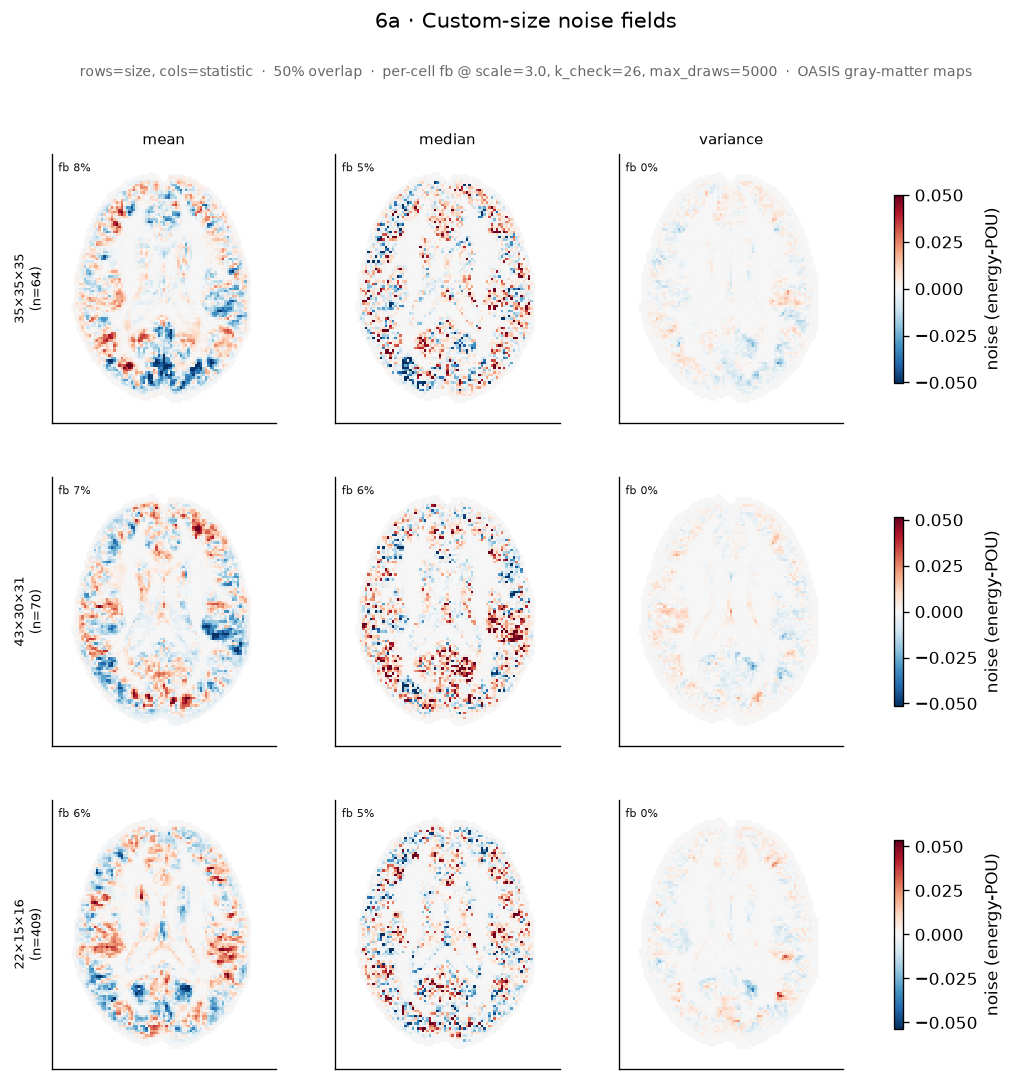

In [29]:
# 6a — noise-field comparison for mean/median/variance (rows=custom size, cols=statistic), 50% overlap
if CS:
    o_use = 0.5 if 0.5 in CUSTOM_OVERLAPS else CUSTOM_OVERLAPS[-1]
    fig, axes = plt.subplots(len(CS), len(STATS), figsize=(3.6*len(STATS), 3.3*len(CS)), squeeze=False)
    for i, nm in enumerate(CS):
        allf = np.concatenate([SWC[(st,nm,o_use)]["fields"]["pou_energy"][MASK] for st in STATS])
        vmn, vmx = robust_sym(allf)
        for j, st in enumerate(STATS):
            im = show(axes[i,j], np.where(MASK, SWC[(st,nm,o_use)]["fields"]["pou_energy"], np.nan)[:,:,zc].T,
                      CMAP_DIV, vmin=vmn, vmax=vmx, outline=MASK_AX, title=st if i==0 else None)
            _frj = SWC[(st,nm,o_use)]["fallback_rate"]; _nj = SWC[(st,nm,o_use)]["n_patches"]
            axes[i,j].text(0.03, 0.97, f"fb {_frj:.0%}", transform=axes[i,j].transAxes, va="top", ha="left",
                           fontsize=6.5, color="#111", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.6))
            if j==0:
                axes[i,j].set_ylabel(f"{'×'.join(map(str,CS[nm]))}\n(n={_nj})", fontsize=8)
        plt.colorbar(im, ax=axes[i,:], shrink=0.7, label="noise (energy-POU)")
    dualtitle(fig, "6a · Custom-size noise fields",
              f"rows=size, cols=statistic  ·  {int(o_use*100)}% overlap  ·  per-cell fb @ scale={MECH_SCALE}, "
              f"k_check={MECH_KCHECK}, max_draws={MECH_MAXDRAWS}  ·  {SUBSTRATE}", y_main=1.0, y_sub=0.955)
    plt.show()

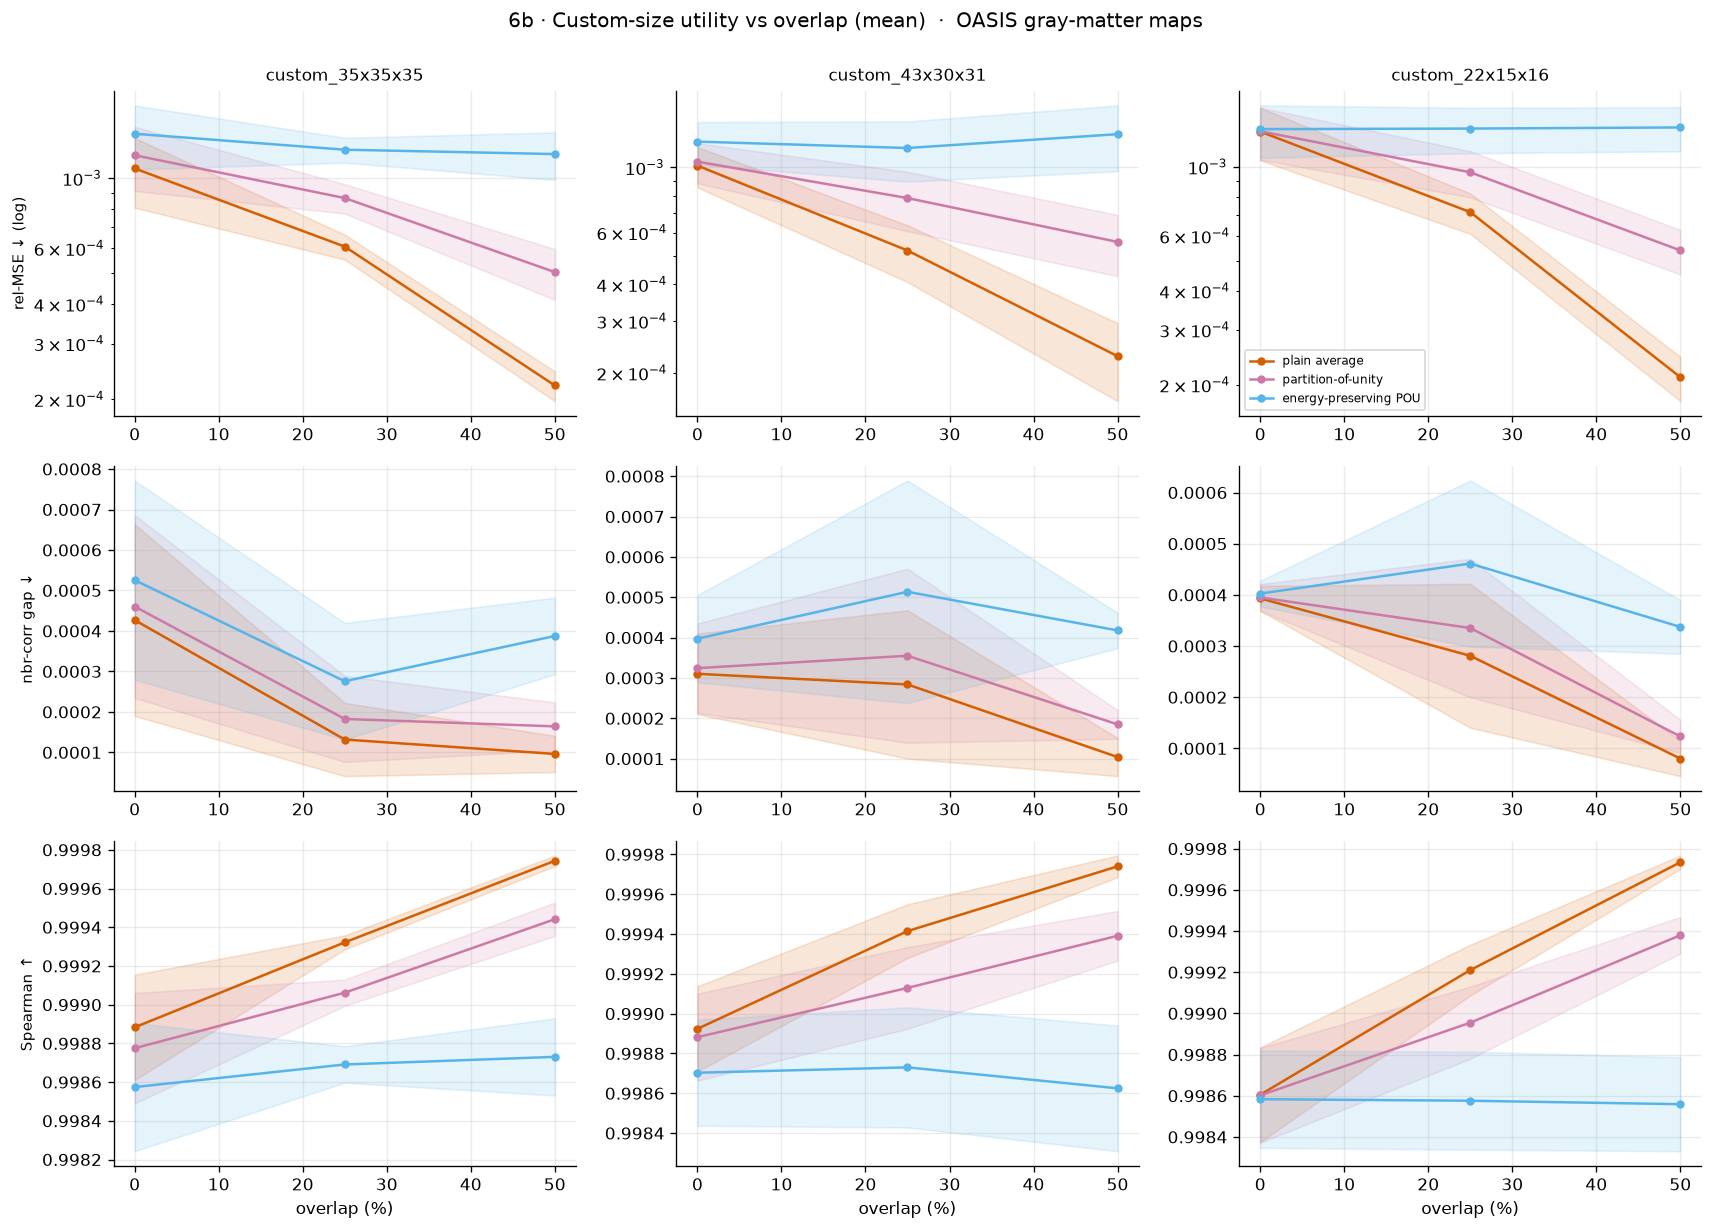

In [30]:
# 6b — utility vs overlap for custom sizes (rel-MSE / gap / Spearman), mean, blend lines
if CS:
    metrics=[("rel_mse","rel-MSE ↓ (log)","log"),("neighbour_corr_gap","nbr-corr gap ↓","linear"),("spearman","Spearman ↑","linear")]
    fig, axes = plt.subplots(len(metrics), len(CS), figsize=(4.8*len(CS), 3.4*len(metrics)), squeeze=False)
    for r,(metric,ylab,scale) in enumerate(metrics):
        for c, nm in enumerate(CS):
            a=axes[r,c]
            for b in BLENDS_REL:
                ys,los,his=[],[],[]
                for o in CUSTOM_OVERLAPS:
                    sub=CUTIL[(CUTIL.stat=="mean")&(CUTIL.shp==nm)&(CUTIL.overlap==o)&(CUTIL.blend==b)]
                    m,lo,hi=ci95(sub[metric].values); ys.append(m); los.append(lo); his.append(hi)
                xx=[int(o*100) for o in CUSTOM_OVERLAPS]
                a.plot(xx,ys,"o-",color=C_BLEND[b],lw=1.5,ms=4,label=BL_DISP[b]); a.fill_between(xx,los,his,color=C_BLEND[b],alpha=0.15)
            a.set_yscale(scale)
            if r==0: a.set_title(nm, fontsize=10)
            if r==len(metrics)-1: a.set_xlabel("overlap (%)")
            if c==0: a.set_ylabel(ylab, fontsize=9)
    axes[0,-1].legend(fontsize=7)
    fig.suptitle(f"6b · Custom-size utility vs overlap (mean)  ·  {SUBSTRATE}", y=1.0); plt.tight_layout(); plt.show()

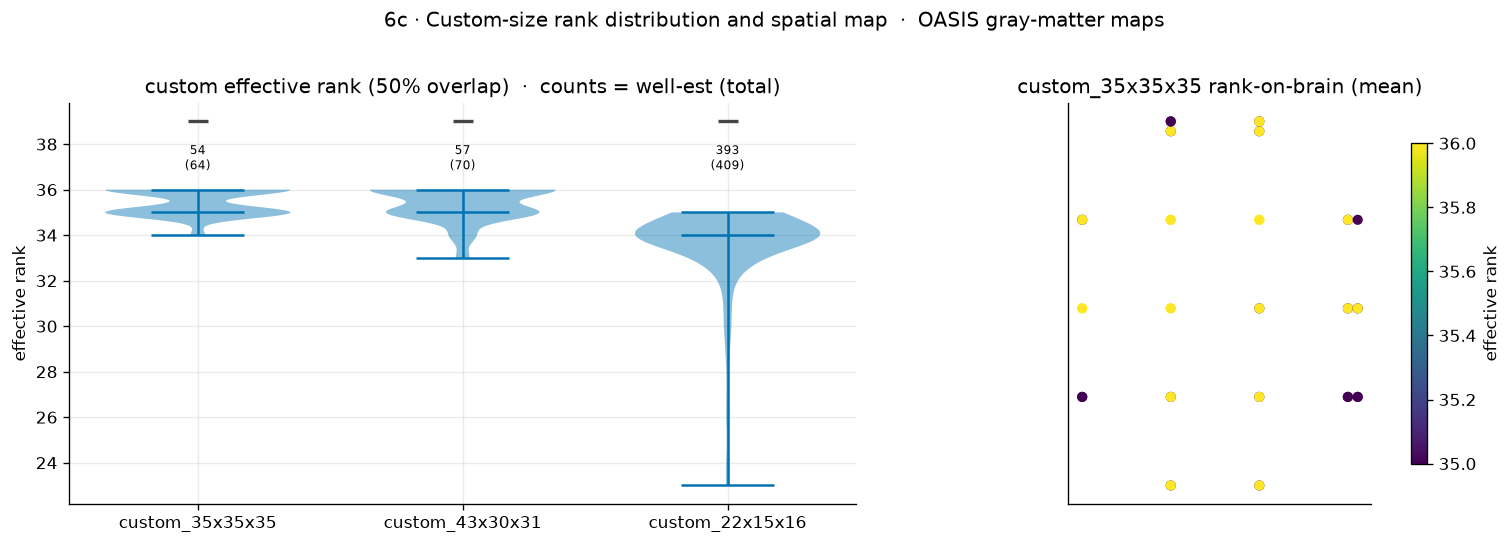

In [31]:
# 6c — rank violins (counts) + rank-on-brain for custom sizes
if CS:
    o_use = 0.5 if 0.5 in CUSTOM_OVERLAPS else CUSTOM_OVERLAPS[-1]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    data=[]; counts=[]
    for nm in CS:
        R=SWC[("mean",nm,o_use)]; q=R["patch_frac"]>=MIN_FRAC
        data.append(R["eff"][q] if q.any() else np.array([0])); counts.append((int(q.sum()),int(len(R["eff"]))))
    parts=axes[0].violinplot(data, showmedians=True, widths=0.7)
    for pc in parts["bodies"]: pc.set_facecolor("#0072B2"); pc.set_alpha(0.45)
    for key in ("cmedians","cbars","cmins","cmaxes"):
        if key in parts: parts[key].set_color("#0072B2")
    for i,nm in enumerate(CS):
        cap=min(int(np.prod(CS[nm])),N-1); axes[0].plot(i+1,cap,"_",color="#444",ms=12,mew=2)
        axes[0].text(i+1, max([d.max() for d in data if len(d)]+[1])*1.02, f"{counts[i][0]}\n({counts[i][1]})", ha="center", va="bottom", fontsize=7)
    axes[0].set_xticks(range(1,len(CS)+1)); axes[0].set_xticklabels(list(CS)); axes[0].set_ylabel("effective rank")
    axes[0].set_title(f"custom effective rank ({int(o_use*100)}% overlap)  ·  counts = well-est (total)")
    nm0=list(CS)[0]; R=SWC[("mean",nm0,o_use)]; q=R["patch_frac"]>=MIN_FRAC; cen=R["centers"][q]; ev=R["eff"][q]
    selz=np.abs(cen[:,2]-zc)<=max(CS[nm0])/2
    sc=axes[1].scatter(cen[selz,0],cen[selz,1],c=ev[selz],cmap=CMAP_RANK,s=26); axes[1].set_aspect("equal")
    axes[1].grid(False); axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].set_title(f"{nm0} rank-on-brain (mean)")
    plt.colorbar(sc, ax=axes[1], shrink=0.8, label="effective rank")
    fig.suptitle(f"6c · Custom-size rank distribution and spatial map  ·  {SUBSTRATE}", y=1.02); plt.tight_layout(); plt.show()

## 7 · Compute demand and parallel scaling

The full release tiles **many** patches, so throughput matters. Here we fix a realistic release config (one
patch size + overlap) and build the whole-brain field with increasing worker counts, to choose a practical
`n_jobs`. BLAS is pinned to one thread per worker (set in §0), so workers do not oversubscribe cores; patch
seeding is deterministic (`SeedSequence([base_seed, patch_idx])`), so results are identical regardless of
worker count. We report **wall time**, **patches/s**, **speed-up vs sequential**, and **peak worker memory**.

*Caveat:* scaling is machine-dependent — on a 2-core box parallelism is pure overhead; the representative
numbers come from a many-core environment (set `NJOBS` and `PAR_WORKERS` accordingly).

machine cores=72 | workers tested=[1, 2, 4, 8, 16, 32] | peak mem = process-tree RSS (psutil)

workload 8³: 1568 patches at 25% overlap, mean stat
  n_jobs=  1:   11.05s    141.9 patches/s  peak(tree) ~  11403 MB
  n_jobs=  2:    7.64s    205.2 patches/s  peak(tree) ~  11412 MB
  n_jobs=  4:    4.30s    364.5 patches/s  peak(tree) ~   7521 MB
  n_jobs=  8:    3.51s    447.3 patches/s  peak(tree) ~   7985 MB
  n_jobs= 16:    3.26s    480.3 patches/s  peak(tree) ~   9168 MB
  n_jobs= 32:    6.22s    251.9 patches/s  peak(tree) ~  11163 MB

workload 43×30×31: 27 patches at 0% overlap, mean stat
  n_jobs=  1:   10.61s      2.5 patches/s  peak(tree) ~   9951 MB
  n_jobs=  2:    8.29s      3.3 patches/s  peak(tree) ~   9896 MB
  n_jobs=  4:    5.23s      5.2 patches/s  peak(tree) ~   7605 MB
  n_jobs=  8:    4.44s      6.1 patches/s  peak(tree) ~   8655 MB
  n_jobs= 16:    4.07s      6.6 patches/s  peak(tree) ~  11112 MB
  n_jobs= 32:    7.17s      3.8 patches/s  peak(tree) ~  13785 MB

work

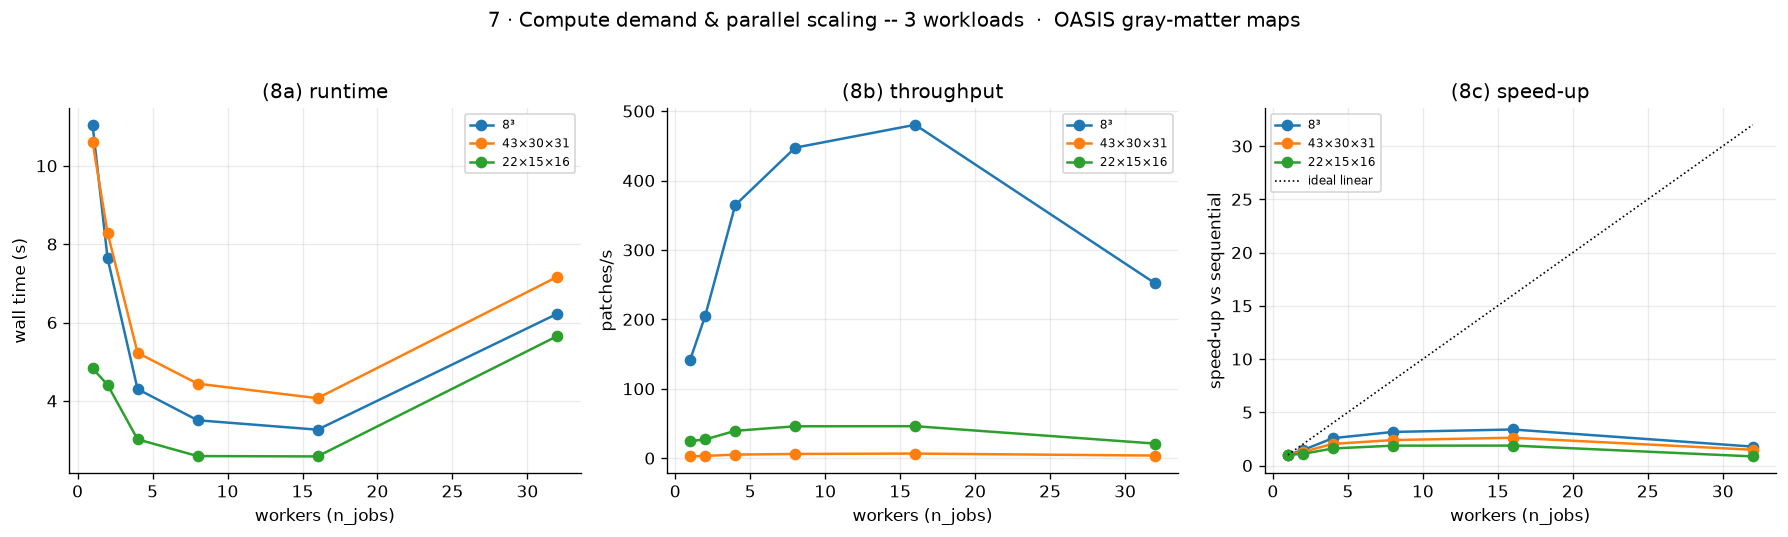


[read-off] 8³ fastest at n_jobs=16 (3.3s, 3.4×). Speed-up saturates well before 72 cores -- worker startup + pickling the 289 MB cohort to each worker dominate past the knee. Peak tree RSS: 22×15×16 ~11670MB, 43×30×31 ~13785MB, 8³ ~11412MB. Practical POC: n_jobs near each workload's knee (~16 here), not the maximum; BLAS pinned to 1 thread/worker.


In [ ]:
# 8 -- parallel scaling at fixed release configs (mode-eigen). Three workloads: the production cube,
# the ORIGINAL anisotropic custom, and its SCALED-DOWN counterpart. Within each, patch workload and
# mechanism settings are fixed across worker counts. Peak memory is sampled over the whole PROCESS TREE
# (parent + joblib workers) -- the old RUSAGE_SELF high-water mark was parent-only and identical for all.
import resource, multiprocessing as _mp, threading
try:
    import psutil; _HAVE_PS = True
except Exception:
    _HAVE_PS = False
_ncpu = _mp.cpu_count()
_aniso   = (43, 30, 31)
_aniso_s = _aniso_small
PAR_WORKLOADS = [("8³", (8, 8, 8), 0.25),
                 (f"{_aniso[0]}×{_aniso[1]}×{_aniso[2]}", _aniso, 0.0),
                 (f"{_aniso_s[0]}×{_aniso_s[1]}×{_aniso_s[2]}", _aniso_s, 0.0)]
PAR_STAT = "mean"
PAR_WORKERS = sorted({w for w in [1, 2, 4, 8, 16, 24, 32] if w <= max(NJOBS, _ncpu)})

def _tree_rss_mb():
    p = psutil.Process(); tot = p.memory_info().rss
    for c in p.children(recursive=True):
        try: tot += c.memory_info().rss
        except Exception: pass
    return tot / 1e6

class _MemSampler(threading.Thread):
    def __init__(self): super().__init__(daemon=True); self.peak = 0.0; self.stop = False
    def run(self):
        while not self.stop:
            if _HAVE_PS:
                try: self.peak = max(self.peak, _tree_rss_mb())
                except Exception: pass
            time.sleep(0.05)

print(f"machine cores={_ncpu} | workers tested={PAR_WORKERS} | peak mem = "
      f"{'process-tree RSS (psutil)' if _HAVE_PS else 'parent-only RUSAGE (psutil absent)'}")
rows = []
for wl_name, wl_ps, wl_ov in PAR_WORKLOADS:
    n_patch = len(T.tile_boxes(VOLSHAPE, wl_ps, wl_ov, MASK, MIN_FRAC)[0])
    print(f"\nworkload {wl_name}: {n_patch} patches at {int(wl_ov*100)}% overlap, {PAR_STAT} stat")
    for w in PAR_WORKERS:
        smp = _MemSampler(); smp.start(); t0 = time.perf_counter()
        _ = A_FIELD(COHORT[SEEDS[0]], MASK, PAR_STAT, wl_ps, wl_ov, base_seed=0, min_frac=MIN_FRAC, n_jobs=w)
        dt = time.perf_counter() - t0; smp.stop = True; smp.join()
        pk = smp.peak if (_HAVE_PS and smp.peak > 0) else resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024.0
        rows.append({"workload": wl_name, "workers": w, "seconds": dt,
                     "patches_per_s": n_patch/dt, "peak_tree_MB": pk, "n_patch": n_patch})
        print(f"  n_jobs={w:>3}: {dt:7.2f}s  {n_patch/dt:7.1f} patches/s  peak(tree) ~{pk:7.0f} MB")
PAR = pd.DataFrame(rows)
for wl_name, _, _ in PAR_WORKLOADS:
    m = PAR.workload == wl_name
    seq = PAR.loc[m & (PAR.workers == PAR.loc[m, "workers"].min()), "seconds"].iloc[0]
    PAR.loc[m, "speedup"] = seq / PAR.loc[m, "seconds"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for wl_name, _, _ in PAR_WORKLOADS:
    s = PAR[PAR.workload == wl_name].sort_values("workers")
    ax[0].plot(s.workers, s.seconds, "o-", label=wl_name)
    ax[1].plot(s.workers, s.patches_per_s, "o-", label=wl_name)
    ax[2].plot(s.workers, s.speedup, "o-", label=wl_name)
ax[0].set(xlabel="workers (n_jobs)", ylabel="wall time (s)", title="(8a) runtime"); ax[0].legend(fontsize=7)
ax[1].set(xlabel="workers (n_jobs)", ylabel="patches/s", title="(8b) throughput"); ax[1].legend(fontsize=7)
ax[2].plot(PAR_WORKERS, PAR_WORKERS, "k:", lw=1, label="ideal linear")
ax[2].set(xlabel="workers (n_jobs)", ylabel="speed-up vs sequential", title="(8c) speed-up"); ax[2].legend(fontsize=7)
fig.suptitle(f"7 · Compute demand & parallel scaling -- 3 workloads  ·  {SUBSTRATE}", y=1.03)
plt.tight_layout(); plt.show()
_b8 = PAR[PAR.workload == "8³"]; _best = _b8.loc[_b8.seconds.idxmin()]
_memtab = PAR.groupby("workload").peak_tree_MB.max()
print(f"\n[read-off] 8³ fastest at n_jobs={int(_best.workers)} ({_best.seconds:.1f}s, {_best.speedup:.1f}×). "
      f"Speed-up saturates well before {_ncpu} cores -- worker startup + pickling the "
      f"{COHORT[0].nbytes/1e6:.0f} MB cohort to each worker dominate past the knee. "
      f"Peak tree RSS: " + ", ".join(f"{k} ~{v:.0f}MB" for k, v in _memtab.items()) + ". "
      f"Practical POC: n_jobs near each workload's knee (~16 here), not the maximum; BLAS pinned to 1 thread/worker.")